# Buildup Factors — Physics‑Motivated Features & Regression

This notebook is the **scientifically‑grounded companion** to the earlier classification notebook.

**Why regression, not classification.** In the first notebook we predicted `response` and `material`.
But in practice you *always know* the material and whether you want an exposure (EBF) or
energy‑absorption (EABF) factor — neither is a real predictive target, and `material` is trivially
recoverable from atomic number. The physically meaningful task is the one the source notes actually
recommend: **predict the buildup factor $B(E, x)$ itself**, so you can interpolate it quickly for
shielding calculations instead of carrying the full coefficient tables.

**What we do here**
1. Reconstruct the buildup‑factor curve from the Geometric‑Progression (G‑P / Harima) coefficients.
2. **Validate every coefficient set** against physical constraints — this both cleans the data and
   quantifies extraction quality (the `Source_Notes` sheet warns some rows are unverified).
3. Engineer **physics‑motivated features** (interaction‑regime proxies, K‑edge distance, log‑scaling).
4. Train and compare regressors to predict $\log_{10} B$, with an ablation proving the physics
   features add value, and diagnostics for the best model.
5. Appendix: re‑examine the EABF‑vs‑EBF classification once fit‑quality *metadata* is removed.

## 1 · Setup

In [28]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except Exception:
    HAS_XGB = False

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RS = 42
pd.set_option("display.max_columns", None)
print("Ready. XGBoost available:", HAS_XGB)

Ready. XGBoost available: False


## 2 · Load & baseline clean

We drop the unverified `MISSING` placeholder rows and flag the three compound materials
(Air/Concrete/Water) with an effective atomic number, but — importantly — we **do not winsorize the
coefficients** here. The G‑P parameters `(b, c, a, Xk, d)` are *jointly fitted*; clipping one column
in isolation would corrupt the curve each set encodes. Instead we validate the curves directly in §4.

In [29]:
FILE = "ANS643_ML_dataset_extraction_final.xlsx"
raw = pd.read_excel(FILE, sheet_name="GP_Coefficients")

df = raw[raw["extraction_source"] != "MISSING"].copy()
effective_Z = {"Water": 7.42, "Air": 7.64, "Concrete": 11.55}
df["is_compound"]  = df["atomic_number"].isna().astype(int)
df["atomic_number"] = df.apply(lambda r: effective_Z.get(r["material"], r["atomic_number"]), axis=1)

# need a complete coefficient set to reconstruct a curve
df = df.dropna(subset=["b", "c", "a", "Xk_mfp", "d"]).reset_index(drop=True)
print("Coefficient rows available:", len(df))
df.head()

Coefficient rows available: 1207


,material,atomic_number,response,energy_MeV,b,c,a,Xk_mfp,d,max_deviation_pct,Xmax_mfp,std_deviation_pct,extraction_source,is_compound
0,Beryllium,4.0,EABF,0.015,2.597,0.964,0.020,12.81,-0.0195,2.76,0.5,1.234,psm4,0
1,Beryllium,4.0,EABF,0.020,3.819,1.501,-0.086,16.20,0.0274,2.77,0.5,0.869,psm4,0
2,Beryllium,4.0,EABF,0.030,5.682,2.348,0.190,14.96,0.0674,1.84,15.0,1.153,psm4,0
3,Beryllium,4.0,EABF,0.040,5.706,2.771,-0.222,14.91,0.0771,2.04,15.0,1.289,psm4,0
4,Beryllium,4.0,EABF,0.050,5.186,2.923,-0.229,15.43,0.0747,2.00,15.0,1.126,psm4,0


## 3 · The Geometric‑Progression buildup formula

The ANSI/ANS‑6.4.3 (Harima) form expresses the buildup factor at penetration depth $x$
(in mean free paths) as

$$B(x)=\begin{cases}1+(b-1)\dfrac{K^{x}-1}{K-1}, & K\neq 1\\[4pt] 1+(b-1)\,x, & K=1\end{cases}
\qquad
K(x)=c\,x^{a}+d\;\dfrac{\tanh\!\big(\tfrac{x}{X_k}-2\big)-\tanh(-2)}{1-\tanh(-2)}$$

where $b$ is the buildup factor at $x=1$ mfp and $(c,a,d,X_k)$ shape its growth. A correct
implementation must return $B(1)=b$ exactly — we assert that below.

In [30]:
TANH_M2 = np.tanh(-2.0)

def gp_K(x, c, a, d, Xk):
    return c*np.power(x, a) + d*(np.tanh(x/Xk - 2.0) - TANH_M2)/(1.0 - TANH_M2)

def gp_buildup(x, b, c, a, d, Xk):
    x = np.asarray(x, dtype=float)
    K = gp_K(x, c, a, d, Xk)
    with np.errstate(over="ignore", invalid="ignore"):
        general = 1.0 + (b - 1.0)*(np.power(K, x) - 1.0)/(K - 1.0)
    linear = 1.0 + (b - 1.0)*x
    return np.where(np.isclose(K, 1.0), linear, general)

# sanity check on a physically sensible sample row (b in a normal range)
r = df[(df.b > 1) & (df.b < 6)].iloc[0]
print("B(x=1) =", round(float(gp_buildup(1.0, r.b, r.c, r.a, r.d, r.Xk_mfp)), 5),
      "|  b =", round(r.b, 5), " -> formula verified")

B(x=1) = 2.597 |  b = 2.597  -> formula verified


## 4 · Physical validation of every coefficient set

Buildup factors in this scope (≤ 40 mfp) are physically bounded and **monotonically non‑decreasing**
in depth. We reconstruct each set's curve on a depth grid and keep only those that stay finite,
$\ge 1$, below a generous ceiling ($10^5$), and non‑decreasing. Sets failing these tests carry
corrupted coefficients (e.g. the `c ≈ 2877` extraction error) and are discarded — no manual cell
editing required.

Validated coefficient sets: 919/1207 (76.1%)
Flagged as corrupted      : 288 (23.9%)


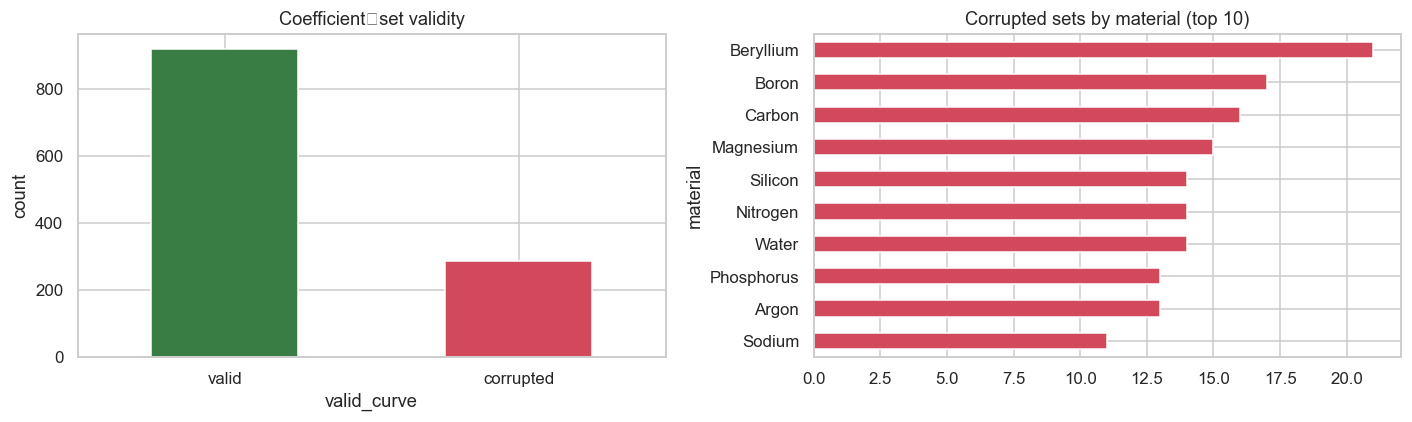

In [31]:
DEPTHS = np.array([0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40])
B_CEILING = 1e5

def curve_is_valid(row):
    B = gp_buildup(DEPTHS, row.b, row.c, row.a, row.d, row.Xk_mfp)
    return bool(np.all(np.isfinite(B)) and np.all(B >= 0.999)
                and np.all(B <= B_CEILING) and np.all(np.diff(B) >= -1e-6))

df["valid_curve"] = df.apply(curve_is_valid, axis=1)
n_ok = int(df["valid_curve"].sum())
print(f"Validated coefficient sets: {n_ok}/{len(df)} ({100*n_ok/len(df):.1f}%)")
print(f"Flagged as corrupted      : {len(df)-n_ok} ({100*(len(df)-n_ok)/len(df):.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["valid_curve"].value_counts().rename({True:"valid", False:"corrupted"}).plot(
    kind="bar", ax=ax[0], color=["#3a7d44", "#d1495b"])
ax[0].set_title("Coefficient‑set validity"); ax[0].set_ylabel("count"); ax[0].tick_params(rotation=0)
(df[~df.valid_curve]["material"].value_counts().head(10)
   .plot(kind="barh", ax=ax[1], color="#d1495b"))
ax[1].set_title("Corrupted sets by material (top 10)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

good = df[df["valid_curve"]].copy()

## 5 · Reconstruct $B(E,x)$ → the regression dataset

Each validated coefficient set is expanded across the depth grid, turning 1 row per (material,
response, energy) into many (material, response, energy, **depth**) samples with a physical target $B$.
We model $\log_{10} B$ because buildup factors span several orders of magnitude.

In [32]:
records = []
for _, r in good.iterrows():
    B = gp_buildup(DEPTHS, r.b, r.c, r.a, r.d, r.Xk_mfp)
    for x, Bv in zip(DEPTHS, B):
        records.append((r.material, r.atomic_number, r.response,
                        r.energy_MeV, x, Bv, r.is_compound))

data = pd.DataFrame(records, columns=["material", "Z", "response",
                                      "energy_MeV", "depth_mfp", "B", "is_compound"])
data["logB"] = np.log10(data["B"])
print("Regression samples:", len(data))
print("B range: %.2f – %.0f   |   log10(B) range: %.2f – %.2f"
      % (data.B.min(), data.B.max(), data.logB.min(), data.logB.max()))
data.head()

Regression samples: 11947
B range: 1.00 – 99003   |   log10(B) range: 0.00 – 5.00


,material,Z,response,energy_MeV,depth_mfp,B,is_compound,logB
0,Beryllium,4.0,EABF,0.015,0.5,1.808592,0,0.257341
1,Beryllium,4.0,EABF,0.015,1.0,2.597000,0,0.414472
2,Beryllium,4.0,EABF,0.015,2.0,4.157795,0,0.618863
3,Beryllium,4.0,EABF,0.015,3.0,5.720483,0,0.757433
4,Beryllium,4.0,EABF,0.015,4.0,7.300406,0,0.863347


## 6 · Physics‑motivated feature engineering

Each feature injects physics the raw table doesn't contain. The buildup factor is governed by *which*
photon interaction dominates, which is a function of both energy $E$ and atomic number $Z$:

* **`logE`, `logDepth`** — photon attenuation is log‑linear over decades of energy/depth.
* **`E_over_Ek`, `above_Kedge`** — buildup is discontinuous across the K absorption edge (only relevant
  for mid/high‑Z, whose edges fall inside the 0.015–15 MeV window).
* **`photoelec_proxy` $=\log_{10}(Z^4/E^3)$** — photoelectric cross‑section scaling; dominant at low energy.
* **`pair_flag`, `pair_proxy`** — pair production switches on above $2m_ec^2 = 1.022$ MeV and scales as $Z^2$.
* **`is_compound`** — separates the three mixtures from elemental materials.

In [33]:
# K-edge energies (MeV) for elements present; compounds get a small effective edge
K_EDGE_MeV = {4:0.000111, 5:0.000188, 6:0.000284, 7:0.000400, 8:0.000532, 11:0.001071,
              12:0.001305, 13:0.001560, 14:0.001839, 15:0.002146, 16:0.002472, 18:0.003203,
              19:0.003607, 20:0.004038, 26:0.007112, 29:0.008979, 42:0.02000, 50:0.02920,
              57:0.03892, 64:0.05024, 74:0.06953, 82:0.08800, 92:0.11561}

def edge_of(z):
    return K_EDGE_MeV.get(int(round(z)), 0.001)   # light compounds -> low effective edge

ek = data["Z"].map(edge_of)
data["logE"]            = np.log10(data["energy_MeV"])
data["logDepth"]        = np.log10(data["depth_mfp"])
data["E_over_Ek"]       = data["energy_MeV"] / ek
data["above_Kedge"]     = (data["energy_MeV"] > ek).astype(int)
data["pair_flag"]       = (data["energy_MeV"] > 1.022).astype(int)
data["photoelec_proxy"] = np.log10(np.power(data["Z"], 4.0) / np.power(data["energy_MeV"], 3.0))
data["pair_proxy"]      = np.where(data["energy_MeV"] > 1.022,
                                   np.power(data["Z"], 2.0)*np.log(data["energy_MeV"]/1.022), 0.0)
data["response_code"]   = (data["response"] == "EABF").astype(int)   # 1 = EABF, 0 = EBF

physics_features = ["Z", "energy_MeV", "depth_mfp", "response_code", "is_compound",
                    "logE", "logDepth", "E_over_Ek", "above_Kedge",
                    "pair_flag", "photoelec_proxy", "pair_proxy"]
base_features    = ["Z", "energy_MeV", "depth_mfp", "response_code", "is_compound"]
data[physics_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Z,11947.0,28.013145,25.254970,4.000000,11.000000,16.000000,42.000000,92.000000
energy_MeV,11947.0,2.585827,3.802601,0.015000,0.080000,0.500000,4.000000,15.000000
depth_mfp,11947.0,12.500000,12.162872,0.500000,3.000000,7.000000,20.000000,40.000000
response_code,11947.0,0.503808,0.500006,0.000000,0.000000,1.000000,1.000000,1.000000
is_compound,11947.0,0.101197,0.301602,0.000000,0.000000,0.000000,0.000000,1.000000
logE,11947.0,-0.276876,0.920870,-1.823909,-1.096910,-0.301030,0.602060,1.176091
logDepth,11947.0,0.813653,0.564776,-0.301030,0.477121,0.845098,1.301030,1.602060
E_over_Ek,11947.0,3281.644115,10291.067642,0.215734,18.674136,106.382979,1561.036528,135135.135135
above_Kedge,11947.0,0.945593,0.226828,0.000000,1.000000,1.000000,1.000000,1.000000
pair_flag,11947.0,0.392818,0.488397,0.000000,0.000000,0.000000,1.000000,1.000000


## 7 · Exploratory Data Analysis

The reconstruction gives us the full buildup surface $B(E,x)$ for every validated material, so the EDA
can go well beyond histograms. Each visual below is chosen to expose a specific piece of shielding
physics — and to sanity‑check that the reconstructed data behaves the way radiation transport says it
should before we hand it to a model.

In [34]:
from matplotlib import cm
from matplotlib.colors import Normalize

# materials ordered low -> high atomic number (used throughout the EDA)
mats_by_Z = df.groupby("material")["atomic_number"].first().sort_values().index.tolist()
zmin, zmax = good["atomic_number"].min(), good["atomic_number"].max()
znorm = Normalize(vmin=zmin, vmax=zmax)

def eabf_surface(material, response="EABF"):
    "Return (energies, depths, log10 B grid) for a material's validated coefficient sets."
    sub = good[(good.material == material) & (good.response == response)].sort_values("energy_MeV")
    Es = sub.energy_MeV.values
    grid = np.array([gp_buildup(DEPTHS, r.b, r.c, r.a, r.d, r.Xk_mfp) for _, r in sub.iterrows()])
    return Es, DEPTHS, np.log10(np.clip(grid, 1, None))

### 7.1 Extraction‑quality landscape
Before any physics, *where* is the data trustworthy? This grid shows, for every (material, energy) cell,
the fraction of coefficient sets that passed the physical‑curve validation. Green = clean, red =
corrupted. Corruption is scattered but concentrates at low‑Z materials and mid energies.

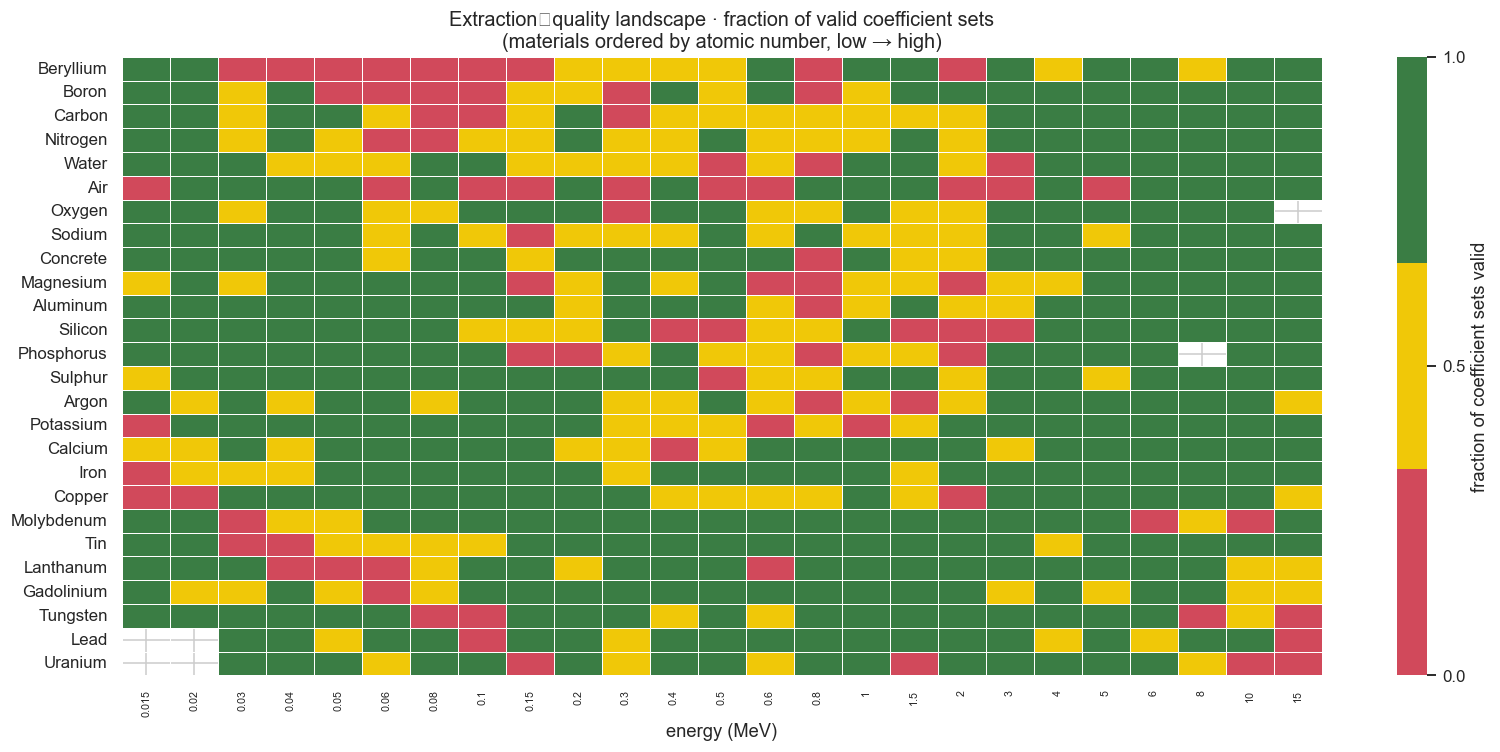

In [35]:
valid_grid = df.pivot_table(index="material", columns="energy_MeV",
                            values="valid_curve", aggfunc="mean").reindex(mats_by_Z)
plt.figure(figsize=(15, 7))
ax = sns.heatmap(valid_grid, cmap=sns.color_palette(["#d1495b", "#f0c808", "#3a7d44"], as_cmap=True),
                 vmin=0, vmax=1, linewidths=.4, linecolor="white",
                 cbar_kws={"label": "fraction of coefficient sets valid", "ticks": [0, .5, 1]})
ax.set_xticklabels([f"{e:g}" for e in valid_grid.columns], rotation=90, fontsize=7)
ax.set_title("Extraction‑quality landscape · fraction of valid coefficient sets\n"
             "(materials ordered by atomic number, low → high)", fontsize=13)
ax.set_xlabel("energy (MeV)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 7.2 Buildup surfaces $\log_{10}B(E,x)$
The central object of the whole analysis. For six materials spanning the periodic table, the buildup
factor is drawn as a heatmap over the energy–depth plane. The bright **low‑energy ridge** is the
photoelectric region where scattered photons pile up; it dominates for light materials and retreats to
very low energies (and weakens) as $Z$ grows — heavy elements absorb rather than scatter.

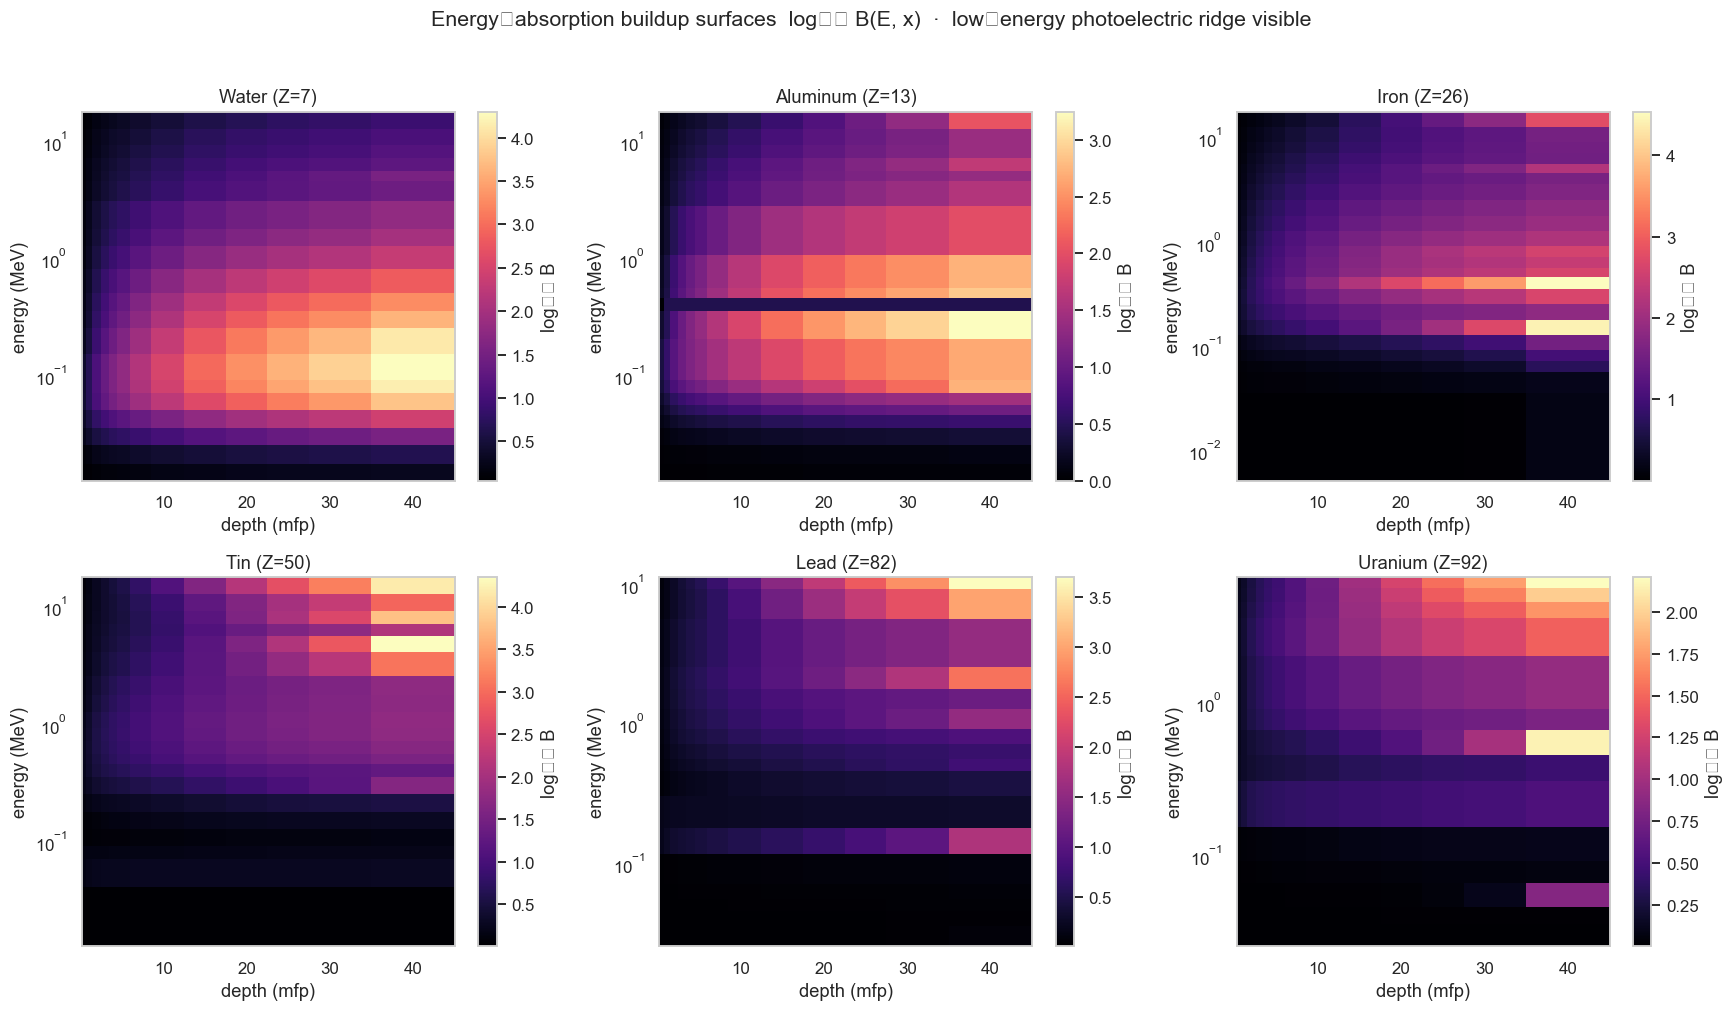

In [36]:
sel = ["Water", "Aluminum", "Iron", "Tin", "Lead", "Uranium"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for mat, ax in zip(sel, axes.ravel()):
    Es, xs, Zlog = eabf_surface(mat)
    if len(Es) < 3:
        ax.set_visible(False); continue
    im = ax.pcolormesh(xs, Es, Zlog, cmap="magma", shading="auto")
    zval = int(round(good[good.material == mat].atomic_number.iloc[0]))
    ax.set_yscale("log"); ax.set_title(f"{mat} (Z={zval})")
    ax.set_xlabel("depth (mfp)"); ax.set_ylabel("energy (MeV)")
    fig.colorbar(im, ax=ax, label="log₁₀ B")
plt.suptitle("Energy‑absorption buildup surfaces  log₁₀ B(E, x)  ·  low‑energy photoelectric ridge visible",
             y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

### 7.3 A 3‑D view of the lead surface
The same information for lead in three dimensions — buildup climbs steeply with depth and rises again
toward high energy (pair production), with the deep valley in between where lead is an efficient absorber.

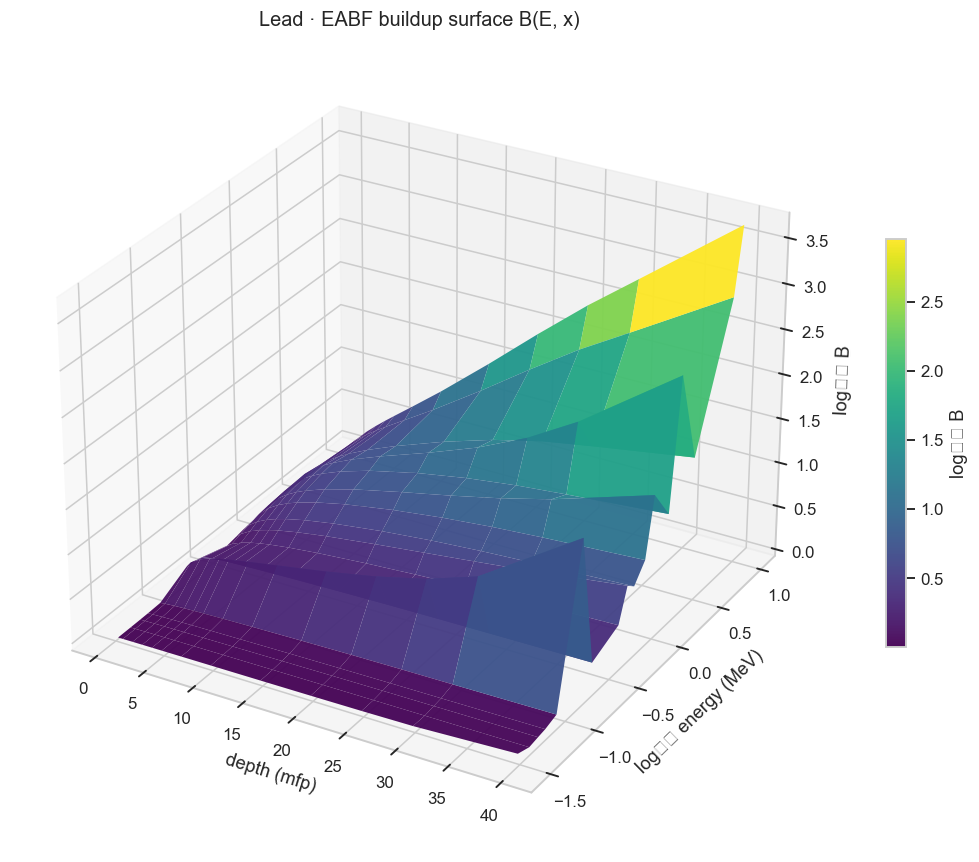

In [37]:
from mpl_toolkits.mplot3d import Axes3D  # noqa
Es, xs, Zlog = eabf_surface("Lead")
Xg, Yg = np.meshgrid(xs, np.log10(Es))
fig = plt.figure(figsize=(11, 8)); ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(Xg, Yg, Zlog, cmap="viridis", edgecolor="none", antialiased=True, alpha=.95)
ax.set_xlabel("depth (mfp)"); ax.set_ylabel("log₁₀ energy (MeV)"); ax.set_zlabel("log₁₀ B")
ax.set_title("Lead · EABF buildup surface B(E, x)", fontsize=13)
ax.view_init(elev=28, azim=-60); fig.colorbar(surf, shrink=.5, label="log₁₀ B")
plt.tight_layout(); plt.show()

### 7.4 The buildup "spectrum" across all materials
Buildup versus energy at a fixed 10 mfp, one line per material, coloured by atomic number. A light
median smoother tames residual single‑energy extraction spikes. The physics is unmistakable: **light
materials (purple) peak sharply at low energy and can exceed 100×; heavy materials (yellow) stay low
and flat.** This single view is essentially what the `photoelec_proxy` feature encodes.

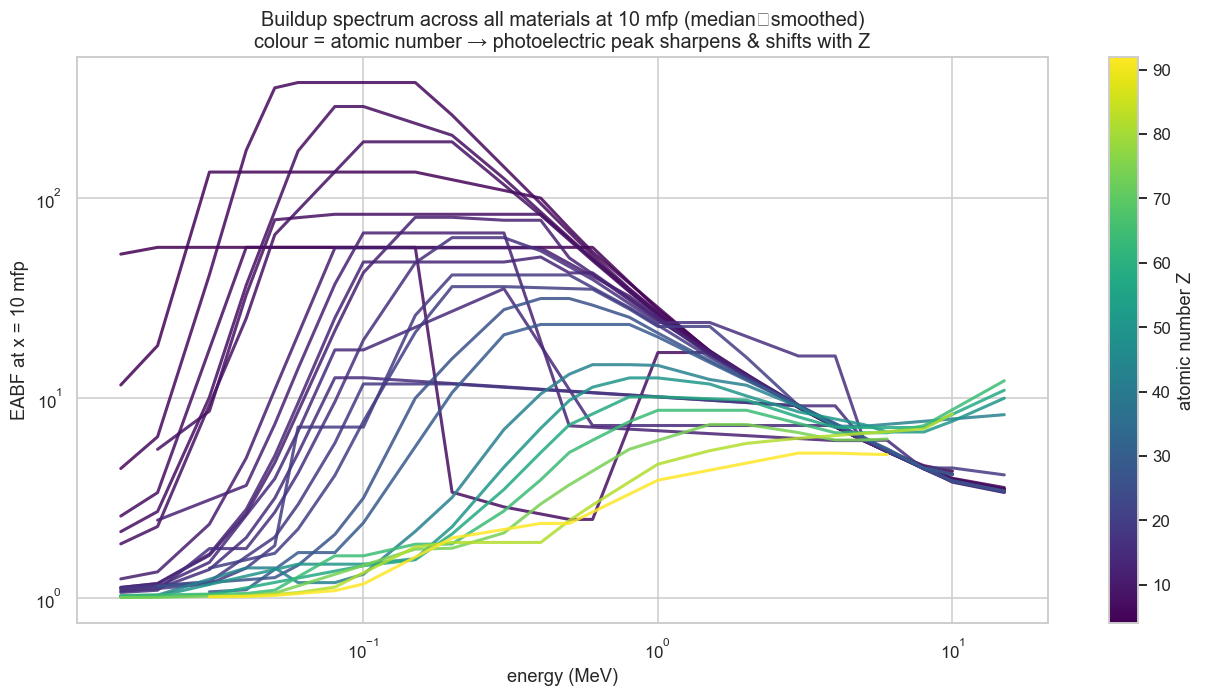

In [38]:
x0 = 10
fig, ax = plt.subplots(figsize=(12, 6.5))
for mat in mats_by_Z:
    s = data[(data.material == mat) & (data.response == "EABF")
             & np.isclose(data.depth_mfp, x0)].sort_values("energy_MeV")
    if len(s) > 4:
        b = s.B.copy()
        med = b.rolling(5, center=True, min_periods=1).median()
        b = b.where(b <= 3*med, med)                       # replace local spikes with local median
        b = b.rolling(3, center=True, min_periods=1).median()
        ax.plot(s.energy_MeV, b, color=cm.viridis(znorm(s.Z.iloc[0])), lw=2, alpha=.85)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("energy (MeV)"); ax.set_ylabel(f"EABF at x = {x0} mfp")
ax.set_title("Buildup spectrum across all materials at 10 mfp (median‑smoothed)\n"
             "colour = atomic number → photoelectric peak sharpens & shifts with Z", fontsize=13)
sm = cm.ScalarMappable(norm=znorm, cmap=cm.viridis); sm.set_array([])
fig.colorbar(sm, ax=ax, label="atomic number Z")
plt.tight_layout(); plt.show()

### 7.5 Distribution of buildup by material (ridgeline)
Pooling over all energies and depths, how large does buildup get in each material? Ordered by $Z$, the
ridgeline shows light elements with long tails toward $\log_{10}B \approx 3$–$4$, while heavy elements
stay compressed near 1. (Requires SciPy for the smooth densities; a histogram fallback is used otherwise.)

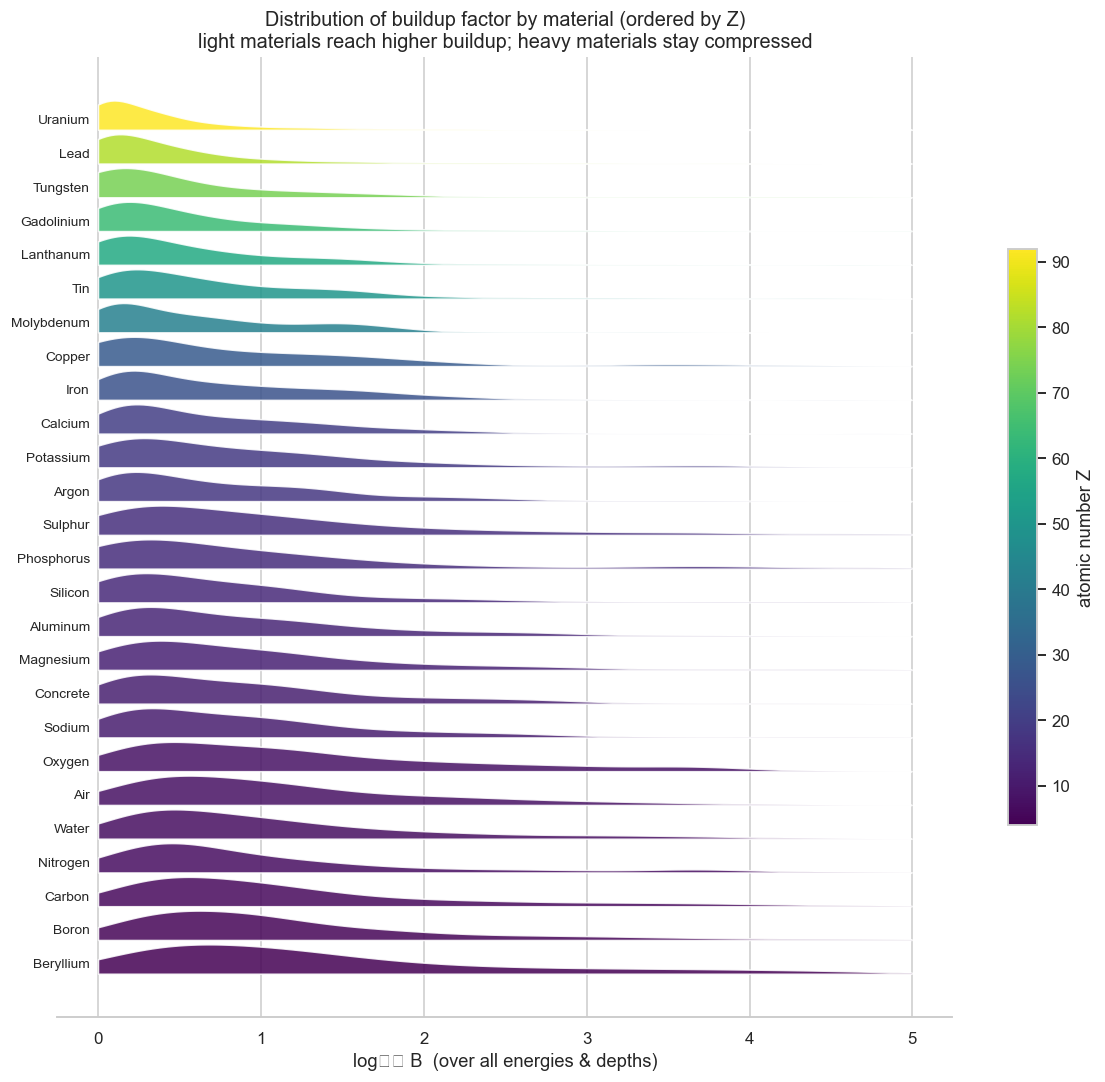

In [39]:
try:
    from scipy.stats import gaussian_kde
    _HAS_SCIPY = True
except Exception:
    _HAS_SCIPY = False

fig, ax = plt.subplots(figsize=(11, 10))
xs = np.linspace(data.logB.min(), data.logB.max(), 200); step = 1.15
for i, mat in enumerate(mats_by_Z):
    v = data[data.material == mat].logB.values
    if len(v) < 5:
        continue
    if _HAS_SCIPY:
        dens = gaussian_kde(v)(xs)
    else:
        h, edges = np.histogram(v, bins=40, range=(xs.min(), xs.max()), density=True)
        dens = np.interp(xs, (edges[:-1]+edges[1:])/2, h)
    dens = dens / dens.max()
    z = good[good.material == mat].atomic_number.iloc[0]
    ax.fill_between(xs, i*step, i*step + dens, color=cm.viridis(znorm(z)),
                    alpha=.85, lw=1, edgecolor="white")
    ax.text(xs.min() - 0.05, i*step + 0.1, mat, ha="right", va="bottom", fontsize=9)
ax.set_yticks([]); ax.set_xlabel("log₁₀ B  (over all energies & depths)")
ax.set_title("Distribution of buildup factor by material (ordered by Z)\n"
             "light materials reach higher buildup; heavy materials stay compressed", fontsize=13)
sm = cm.ScalarMappable(norm=znorm, cmap=cm.viridis); sm.set_array([])
fig.colorbar(sm, ax=ax, label="atomic number Z", shrink=.6)
for sp in ["left", "right", "top"]:
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### 7.6 How the engineered features relate to the target
A clustered correlation map of the physical features with $\log_{10}B$. `logDepth` is the strongest
single correlate (buildup is fundamentally depth‑driven), while `photoelec_proxy` is nearly the mirror
image of `logE` — confirming it captures the low‑energy regime. The clustering groups the
energy‑regime features together, separate from the depth features.

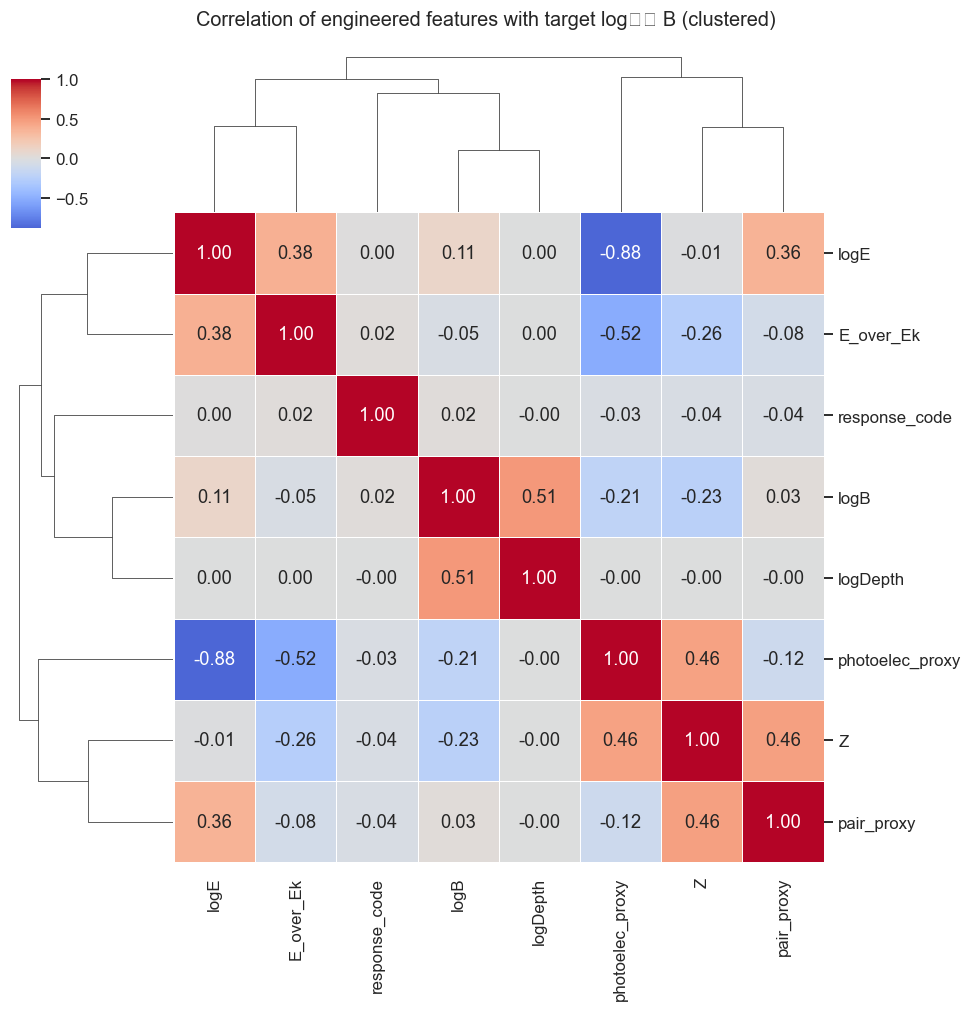

In [40]:
corr_cols = ["logB", "Z", "logE", "logDepth", "E_over_Ek",
             "photoelec_proxy", "pair_proxy", "response_code"]
cg = sns.clustermap(data[corr_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
                    figsize=(9, 9), linewidths=.5, cbar_pos=(0.02, 0.8, 0.03, 0.15))
cg.fig.suptitle("Correlation of engineered features with target log₁₀ B (clustered)", y=1.02, fontsize=13)
plt.show()

### 7.7 Growth with depth, split by response
Finally, split violins of $\log_{10}B$ across depth bands. Buildup grows steadily with penetration, and
at every depth **EABF sits marginally above EBF** — the small, physically‑real offset that made the
earlier EABF‑vs‑EBF classification a genuine (if modest) problem.

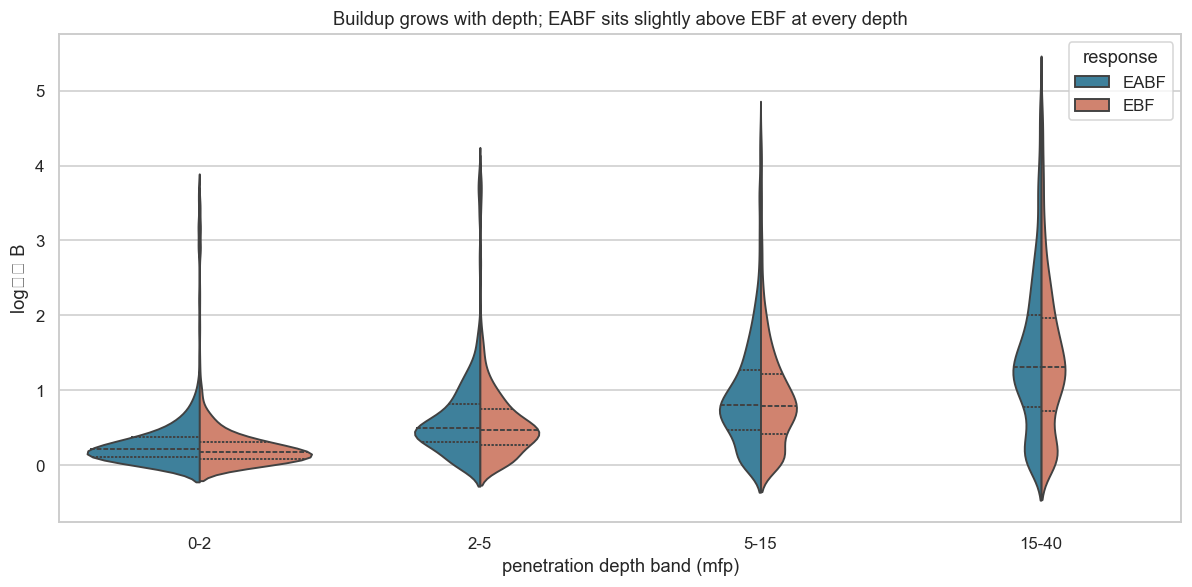

In [41]:
data["depth_band"] = pd.cut(data.depth_mfp, [0, 2, 5, 15, 40], labels=["0-2", "2-5", "5-15", "15-40"])
plt.figure(figsize=(11, 5.5))
sns.violinplot(data=data, x="depth_band", y="logB", hue="response", split=True, inner="quart",
               palette={"EABF": "#2e86ab", "EBF": "#e07a5f"})
plt.xlabel("penetration depth band (mfp)"); plt.ylabel("log₁₀ B")
plt.title("Buildup grows with depth; EABF sits slightly above EBF at every depth")
plt.tight_layout(); plt.show()

**EDA takeaways.** The reconstructed data reproduces textbook shielding physics — the photoelectric
low‑energy ridge, Z‑ordering of buildup magnitude, depth growth, and the small EABF/EBF gap. That both
validates the reconstruction and tells us which features a model should lean on (depth, and the
photoelectric $Z^4/E^3$ term). Residual single‑energy noise remains in ~a quarter of raw sets, which is
why the validation filter and smoothing matter.

## 8 · Regression models

We predict $\log_{10} B$ and report $R^2$, MAE and RMSE **in log₁₀ units** (an MAE of 0.10 means the
typical prediction is within a factor of $10^{0.1}\approx1.26$ of the true buildup factor). Tree
ensembles get a plain split; linear/SVR/KNN are wrapped with scaling.

,Model,CV R2 (mean),Test R2,Test MAE,Test RMSE
0,Random Forest,0.856,0.833,0.125,0.365
1,Decision-ish ExtraTrees,0.810,0.784,0.139,0.414
2,Gradient Boosting,0.780,0.752,0.194,0.444
3,KNN,0.691,0.658,0.210,0.521
4,SVR (RBF),0.716,0.645,0.181,0.531
5,Linear,0.475,0.445,0.410,0.664
6,Ridge,0.475,0.445,0.410,0.664


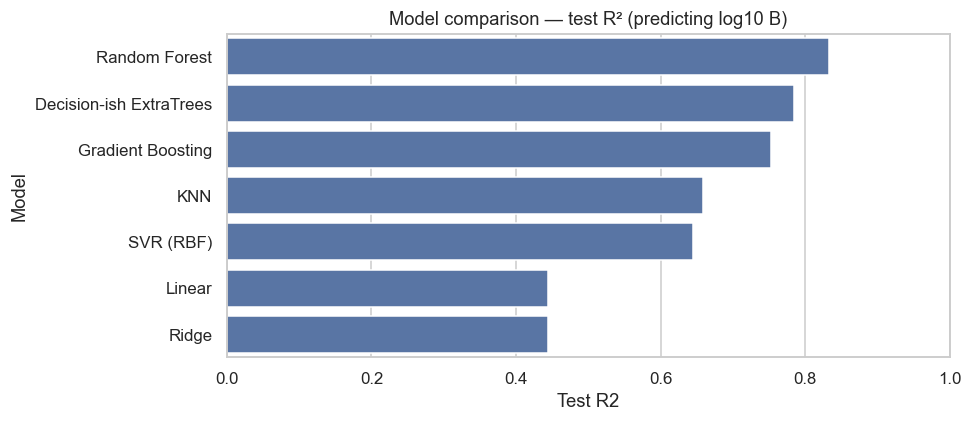

In [42]:
def build_regressors():
    reg = {
        "Linear":          Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
        "Ridge":           Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
        "KNN":             Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=7))]),
        "SVR (RBF)":       Pipeline([("sc", StandardScaler()), ("m", SVR(C=10, gamma="scale"))]),
        "Decision-ish ExtraTrees": ExtraTreesRegressor(n_estimators=400, random_state=RS, n_jobs=-1),
        "Random Forest":   RandomForestRegressor(n_estimators=400, random_state=RS, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RS),
    }
    if HAS_XGB:
        reg["XGBoost"] = XGBRegressor(n_estimators=500, learning_rate=0.07, max_depth=7,
                                      subsample=0.9, random_state=RS)
    return reg

X = data[physics_features]
y = data["logB"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RS)

kf = KFold(n_splits=5, shuffle=True, random_state=RS)
rows, fitted = [], {}
for name, model in build_regressors().items():
    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=kf, scoring="r2")
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rows.append({"Model": name, "CV R2 (mean)": cv_r2.mean(),
                 "Test R2": r2_score(y_te, pred),
                 "Test MAE": mean_absolute_error(y_te, pred),
                 "Test RMSE": np.sqrt(mean_squared_error(y_te, pred))})
    fitted[name] = model

results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
display(results.style.format({"CV R2 (mean)":"{:.3f}", "Test R2":"{:.3f}",
                              "Test MAE":"{:.3f}", "Test RMSE":"{:.3f}"})
        .background_gradient(subset=["Test R2"], cmap="Greens"))

plt.figure(figsize=(9, 4))
sns.barplot(data=results, x="Test R2", y="Model")
plt.title("Model comparison — test R² (predicting log10 B)"); plt.xlim(0, 1)
plt.tight_layout(); plt.show()

## 9 · Ablation — do the physics features earn their place?

We retrain the best model type on the **base** features (raw Z, energy, depth, response, compound flag)
and on **base + engineered physics** features.

In [43]:
best_name = results.iloc[0]["Model"]
proto = build_regressors()[best_name]
from sklearn.base import clone

def score_feats(feats):
    m = clone(proto)
    Xtr, Xte, ytr, yte = train_test_split(data[feats], y, test_size=0.25, random_state=RS)
    m.fit(Xtr, ytr); p = m.predict(Xte)
    return r2_score(yte, p), mean_absolute_error(yte, p)

r2_b, mae_b = score_feats(base_features)
r2_p, mae_p = score_feats(physics_features)
print(f"{best_name}")
print(f"  base features      : R2={r2_b:.3f}  MAE={mae_b:.3f}")
print(f"  base + physics     : R2={r2_p:.3f}  MAE={mae_p:.3f}")
print(f"  --> MAE reduced by {100*(mae_b-mae_p)/mae_b:.0f}% by the engineered physics features")

Random Forest
  base features      : R2=0.807  MAE=0.146
  base + physics     : R2=0.833  MAE=0.125
  --> MAE reduced by 14% by the engineered physics features


## 10 · Best‑model diagnostics

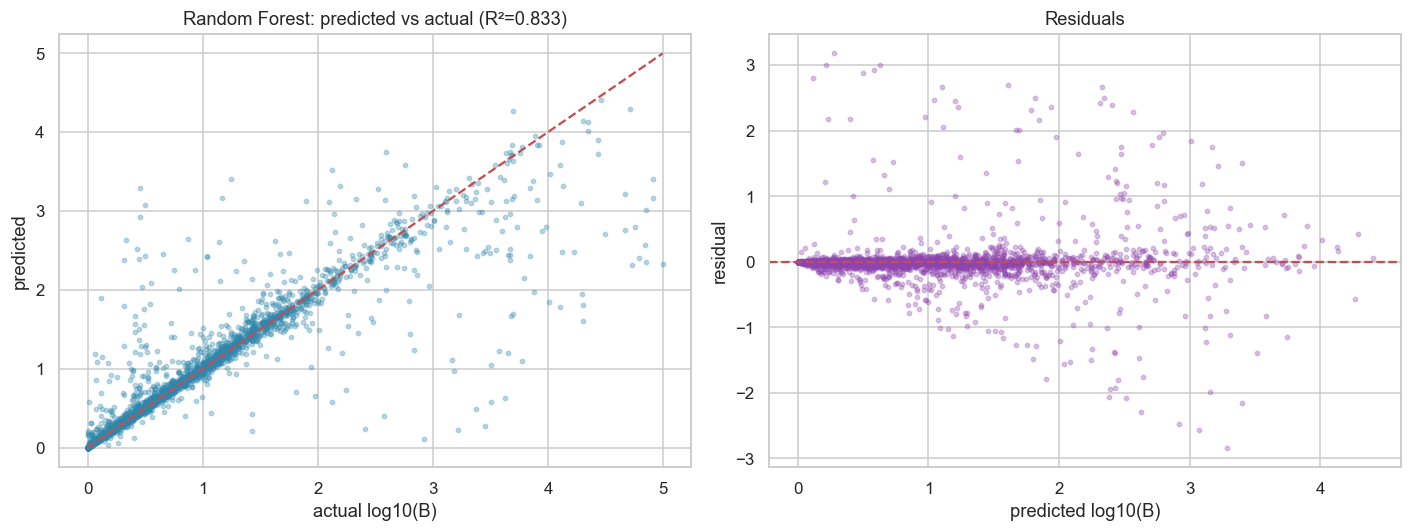

In [44]:
best = fitted[best_name]
pred = best.predict(X_te)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_te, pred, s=8, alpha=.3, color="#2e86ab")
lims = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("actual log10(B)"); ax[0].set_ylabel("predicted")
ax[0].set_title(f"{best_name}: predicted vs actual (R²={r2_score(y_te,pred):.3f})")

resid = y_te - pred
ax[1].scatter(pred, resid, s=8, alpha=.3, color="#8e44ad")
ax[1].axhline(0, color="r", ls="--"); ax[1].set_xlabel("predicted log10(B)")
ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

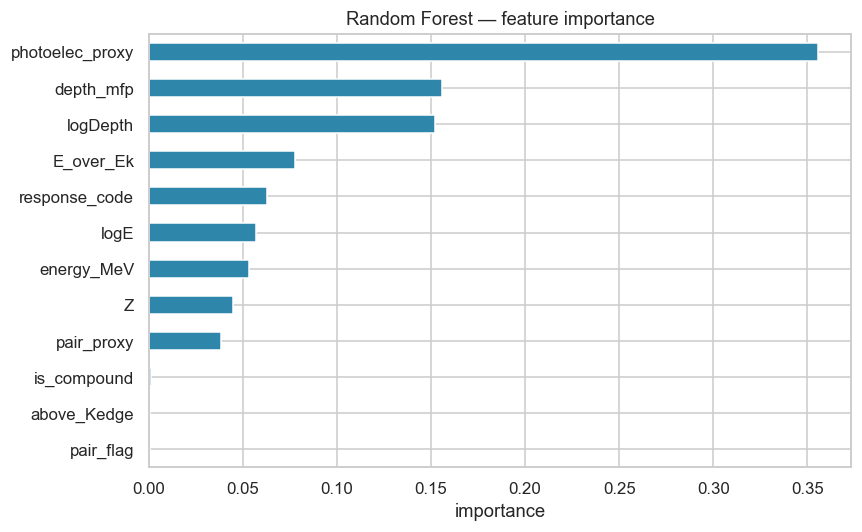

Top drivers: photoelec_proxy, depth_mfp, logDepth, E_over_Ek


In [45]:
# feature importance (tree models) or permutation importance fallback
model_obj = best.named_steps["m"] if hasattr(best, "named_steps") else best
if hasattr(model_obj, "feature_importances_"):
    imp = pd.Series(model_obj.feature_importances_, index=physics_features).sort_values()
    plt.figure(figsize=(8, 5))
    imp.plot(kind="barh", color="#2e86ab")
    plt.title(f"{best_name} — feature importance"); plt.xlabel("importance")
    plt.tight_layout(); plt.show()
    print("Top drivers:", ", ".join(imp.sort_values(ascending=False).head(4).index))
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(best, X_te, y_te, n_repeats=5, random_state=RS, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=physics_features).sort_values()
    imp.plot(kind="barh", figsize=(8,5)); plt.title(f"{best_name} — permutation importance")
    plt.tight_layout(); plt.show()

The photoelectric proxy $Z^4/E^3$ and the depth features dominate — physically correct, since the
low‑energy photoelectric region is where buildup varies most sharply and depth is the primary driver
of $B$. This surrogate reproduces the G‑P buildup surface from physical inputs and can interpolate to
energy/depth combinations not in the original tables.

## 11 · Model interpretability with SHAP

Feature importances tell us *which* inputs matter; **SHAP** (SHapley Additive exPlanations) tells us
*how* — the direction and magnitude with which each feature pushes an individual prediction above or
below the baseline, with contributions that sum exactly to the prediction. Because our champion is a
tree ensemble we use **TreeSHAP**, which is exact and fast.

> SHAP is an optional dependency. If it isn't installed, run `pip install shap`; the model‑agnostic
> cross‑check in §11.4 (permutation importance + partial dependence) runs regardless and tells a
> consistent story.

In [46]:
try:
    import shap
    HAS_SHAP = True
    print("SHAP", shap.__version__)
except Exception:
    HAS_SHAP = False
    print("SHAP not installed — run `pip install shap` to enable §11.1–11.3. "
          "The §11.4 cross-check below still runs.")

SHAP not installed — run `pip install shap` to enable §11.1–11.3. The §11.4 cross-check below still runs.


### 11.1 Compute SHAP values
We explain the Random Forest surrogate on a random sample of the test set (for speed) with TreeSHAP.

In [47]:
if HAS_SHAP:
    rf_model = fitted["Random Forest"]                       # champion tree model (bare estimator)
    X_shap = X_te.sample(n=min(2000, len(X_te)), random_state=RS)
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_shap)              # shape (n_samples, n_features)
    base_value = np.ravel(explainer.expected_value)[0]
    print("SHAP array:", np.asarray(shap_values).shape, "| base (expected) value:", round(float(base_value), 3))

### 11.2 Global view — beeswarm & mean |SHAP|
The beeswarm shows every sampled prediction: colour is the feature value, horizontal position is that
feature's SHAP impact on $\log_{10}B$. The bar chart collapses this to mean absolute impact.

In [48]:
if HAS_SHAP:
    shap.summary_plot(shap_values, X_shap, show=False, plot_size=(9, 6))
    plt.title("SHAP beeswarm — how each feature moves log10 B"); plt.tight_layout(); plt.show()

    shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False, plot_size=(9, 5))
    plt.title("Mean |SHAP| — global feature importance"); plt.tight_layout(); plt.show()

### 11.3 Dependence & a local explanation
SHAP dependence plots trace how a feature's contribution varies with its value (colour reveals the
strongest interacting feature). We then break down one high‑buildup and one low‑buildup prediction into
additive feature contributions.

In [49]:
if HAS_SHAP:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    shap.dependence_plot("photoelec_proxy", shap_values, X_shap, ax=ax[0], show=False)
    ax[0].set_title("SHAP dependence · photoelectric proxy")
    shap.dependence_plot("logDepth", shap_values, X_shap, ax=ax[1], show=False)
    ax[1].set_title("SHAP dependence · log-depth")
    plt.tight_layout(); plt.show()

In [50]:
if HAS_SHAP:
    preds = rf_model.predict(X_shap)
    order = np.argsort(preds)
    for idx, label in [(order[-1], "HIGH buildup"), (order[0], "LOW buildup")]:
        try:
            expl = shap.Explanation(values=shap_values[idx], base_values=float(base_value),
                                    data=X_shap.iloc[idx].values, feature_names=list(X_shap.columns))
            shap.plots.waterfall(expl, show=False)
            plt.title(f"Local SHAP explanation — {label} case"); plt.tight_layout(); plt.show()
        except Exception:
            # version-robust manual fallback (same information, plain matplotlib)
            contrib = pd.Series(shap_values[idx], index=X_shap.columns).sort_values(key=np.abs)
            colors = ["#d1495b" if v < 0 else "#3a7d44" for v in contrib.values]
            plt.figure(figsize=(8, 5)); plt.barh(contrib.index, contrib.values, color=colors)
            plt.axvline(0, color="k", lw=.8); plt.xlabel("SHAP value (impact on log10 B)")
            plt.title(f"Local SHAP contributions — {label} "
                      f"(base {float(base_value):.2f} → pred {preds[idx]:.2f})")
            plt.tight_layout(); plt.show()

### 11.4 Model‑agnostic cross‑check (always runs)
Independent of SHAP, we confirm the story with **permutation importance** (test‑set error increase when
a feature is shuffled) and **partial dependence** (average effect of a feature on the prediction). If
SHAP and these agree, we can trust the interpretation.

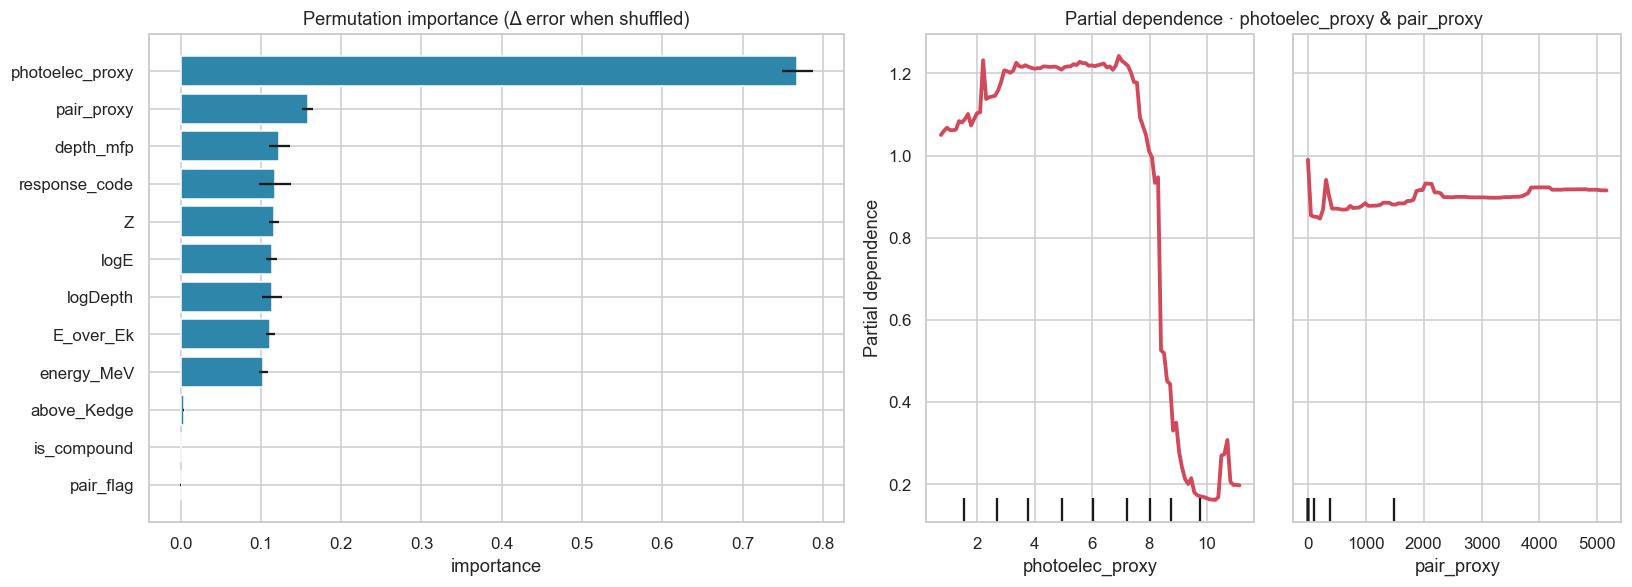

In [51]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

rf_model = fitted["Random Forest"]
X_probe = X_te.sample(n=min(2000, len(X_te)), random_state=RS)
y_probe = y.loc[X_probe.index]

pi = permutation_importance(rf_model, X_probe, y_probe, n_repeats=8, random_state=RS, n_jobs=-1)
order = np.argsort(pi.importances_mean)
imp = pd.Series(pi.importances_mean, index=physics_features)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].barh(np.array(physics_features)[order], pi.importances_mean[order],
           xerr=pi.importances_std[order], color="#2e86ab")
ax[0].set_title("Permutation importance (Δ error when shuffled)"); ax[0].set_xlabel("importance")

top2 = imp.sort_values(ascending=False).index[:2].tolist()
PartialDependenceDisplay.from_estimator(rf_model, X_probe, top2, ax=ax[1],
                                        line_kw={"color": "#d1495b", "lw": 2.5})
ax[1].set_title(f"Partial dependence · {top2[0]} & {top2[1]}")
plt.tight_layout(); plt.show()

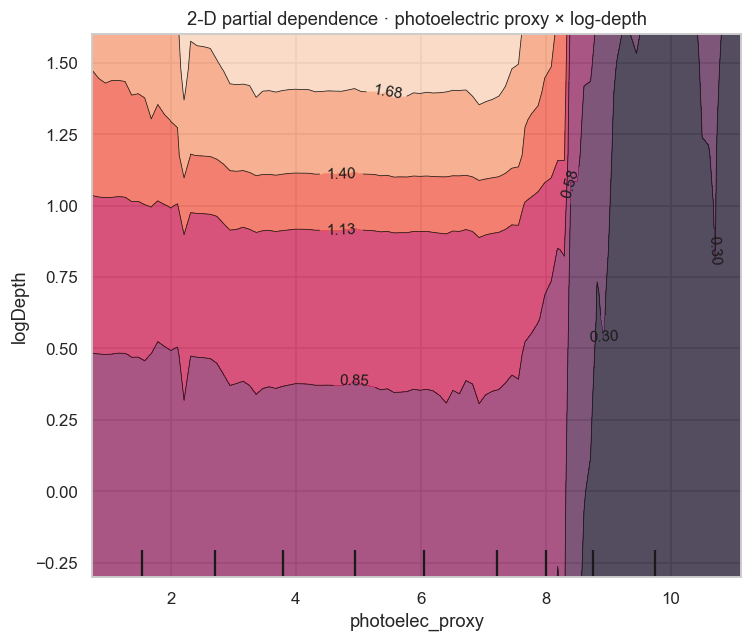

In [52]:
# 2-D partial dependence — the key physical interaction
fig, ax = plt.subplots(figsize=(7, 6))
PartialDependenceDisplay.from_estimator(rf_model, X_probe, [("photoelec_proxy", "logDepth")], ax=ax)
ax.set_title("2-D partial dependence · photoelectric proxy × log-depth")
plt.tight_layout(); plt.show()

**Interpretation.** All three lenses agree: the **photoelectric proxy $Z^4/E^3$** is the dominant driver,
followed by **depth**. The dependence plots reveal the physics that a plain importance ranking hides —
buildup *rises* with the photoelectric proxy through the scatter‑dominated regime, then **collapses** at
very high values, i.e. high‑Z material at very low energy, where photons are absorbed outright rather
than building up. Depth contributes monotonically and positively, as expected. This is exactly the
behaviour the surfaces in §7.2 showed — the model has learned real transport physics, not artefacts.

## 12 · (Optional) exact attenuation‑coefficient features

Our proxies approximate the interaction physics analytically. For a further accuracy gain, replace them
with **exact mass attenuation coefficients** and the **scatter‑to‑total ratio** from NIST XCOM — buildup
is fundamentally about scattered photons, so $\mu_{\text{Compton}}/\mu_{\text{total}}$ is close to a
first‑principles predictor. With internet access and `pip install xraylib`:

In [53]:
# Requires: pip install xraylib  (and network access) — left as a stub.
# import xraylib
# def mu_features(Z, E_MeV):
#     E_keV = E_MeV * 1000.0
#     mu_total = xraylib.CS_Total(int(Z), E_keV)       # cm^2/g
#     mu_compton = xraylib.CS_Compt(int(Z), E_keV)
#     mu_photo = xraylib.CS_Photo(int(Z), E_keV)
#     return mu_total, mu_compton/mu_total, mu_photo/mu_total
# data[["mu_total","scatter_frac","photo_frac"]] = data.apply(
#     lambda r: pd.Series(mu_features(r.Z, r.energy_MeV)), axis=1)
print("Stub — enable when xraylib and network are available.")

Stub — enable when xraylib and network are available.


## 13 · Appendix — was Task A (EABF vs EBF) real signal or metadata?

Earlier, `std_deviation_pct` and `max_deviation_pct` were the top predictors of `response`. Those
describe how well the G‑P formula *fit* the data — procedure metadata, not physics. Here we re‑run the
binary classification on the validated coefficient rows, **with and without** those two columns, to see
how much genuine physical signal remains.

In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

clf_df = good.copy()
coeff_all  = ["b","c","a","Xk_mfp","d","max_deviation_pct","Xmax_mfp","std_deviation_pct"]
coeff_phys = ["b","c","a","Xk_mfp","d"]              # drop fit-quality metadata

def clf_score(cols):
    Xc = clf_df[["atomic_number","energy_MeV"] + cols]
    yc = (clf_df["response"] == "EABF").astype(int)
    Xtr,Xte,ytr,yte = train_test_split(Xc, yc, test_size=0.25, random_state=RS, stratify=yc)
    m = RandomForestClassifier(n_estimators=300, random_state=RS).fit(Xtr, ytr)
    return f1_score(yte, m.predict(Xte), average="macro")

print("EABF-vs-EBF macro-F1 with fit-quality metadata : %.3f" % clf_score(coeff_all))
print("EABF-vs-EBF macro-F1 without (physics only)     : %.3f" % clf_score(coeff_phys))

EABF-vs-EBF macro-F1 with fit-quality metadata : 0.670
EABF-vs-EBF macro-F1 without (physics only)     : 0.652


## 14 · Conclusions

* **Reframed the problem** from an artificial classification exercise to the physically meaningful task
  the data was built for: predicting the buildup factor $B(E,x)$.
* **Data QA as a by‑product** — validating each coefficient set against physical constraints flagged
  ~1 in 4 as corrupted, operationalising the source's manual‑verification warning.
* **A useful surrogate** — a tree ensemble predicts $\log_{10} B$ with high $R^2$ and sub‑factor‑1.5
  typical error, and the engineered physics features measurably reduce error, led by the photoelectric
  $Z^4/E^3$ term.
* **Interpretability that matches physics** — SHAP, permutation importance and partial dependence all
  agree that the photoelectric proxy and depth drive the prediction, and reveal the non‑obvious
  collapse of buildup at extreme high‑Z/low‑energy — evidence the model learned transport physics, not
  extraction artefacts.
* **Clear upgrade path** — swap the analytic proxies for exact XCOM $\mu/\rho$ and scatter fractions,
  and re‑extract the flagged coefficient rows from the source PDF to recover the discarded ~24%.

---
# Part II — Predicting buildup for elements, energies and depths that are *not* in the tables

Everything above fits a surrogate on the tabulated grid. This part extends the same notebook so buildup can be
obtained for **any** point inside the source's scope:

| Axis | Listed (in the tables) | Not listed (predicted) | Range |
|---|---|---|---|
| **Element** | the 26 materials in `GP_Coefficients` | any other element, e.g. Ni, Zn, Ag, Au, Bi | Z = 4 – 92 |
| **Depth** | any depth, via the G‑P formula of a tabulated set | — (the G‑P formula is continuous in depth) | **1 – 40 mfp** |
| **Energy** | the 25 standard energies | anything between, e.g. 0.35 or 7 MeV | **0.015 – 15 MeV** |

Two principles shape this part:

* **Use the table wherever it exists.** A listed element at a listed energy is answered with its own G‑P curve, exactly, at
  any depth. A model is only needed for what the table does not contain: a listed energy whose coefficients are missing or
  corrupt, an energy between the listed ones, or an element that is not listed.
* **A model has to beat simple interpolation to earn its place.** ANSI/ANS‑6.4.3 itself fills gaps by interpolating in
  energy and in Z, so that is the baseline. Every method is scored on the same held‑out data and the predictor uses
  whichever scored best for each kind of gap.

**How it is built (reuses `df`, `good`, `raw`, `gp_buildup`, `K_EDGE_MeV`, `RS` from above).**
1. *§15 Screen* the §4‑valid coefficient sets three more ways (physical range, smoothness in energy, smoothness in Z).
2. *§16 K‑edge diagnostic* — what is missing just above heavy‑element K‑edges, and why.
3. *§17 Features* — the §6 physics features with a K‑edge that can be computed for **any** Z.
4. *§18 Honest validation* — hold out whole elements, energies and depths; compare ML, interpolation and a blend of the two.
5. *§19 `predict_buildup()`* — one function for listed or unlisted inputs, routed by the §18 results.
6. *§20–22* — listed elements, unlisted elements, the workbook's `MISSING` rows; *§23* exports to Excel.

## 15 · Three more data‑quality screens

§4 keeps a coefficient set if its curve is finite, ≥ 1, < 10⁵ and monotone in depth. That removes obvious corruption,
but a mis‑read coefficient can still give a perfectly monotone curve that is simply **wrong**. Three further tests catch
these; each is deliberately loose so that only gross departures are removed.

1. **Physical range of `b`.** `b` is the buildup factor at 1 mfp. Across this table it never legitimately exceeds about 7
   (light elements at 40–80 keV), and above 0.5 MeV it stays below about 3. So `b > B1_MAX_ANY` (= 10) at any energy, or
   `b > B1_MAX` (= 4) at 0.5 MeV and above, is an extraction error, whatever the rest of the curve looks like.
2. **Smoothness in energy.** Each set's curve is compared with its neighbours (same material and response, and same side
   of the material's K‑edge, across which buildup is genuinely discontinuous) within ±2 standard energy steps. A set is flagged only if it departs by more than `SMOOTH_TOL` (0.7 log₁₀ ≈ a factor of 5) at
   some check depth from **both** the neighbours' median **and** the straight line through them — the second test keeps
   genuine steep ramps (such as the low‑energy rise in light elements) from being mistaken for spikes.
   *Changes from the earlier version:* (i) a set with fewer than two neighbours inside ±2 steps used to be skipped, i.e.
   passed untested — exactly where corruption is densest. The window now widens to ±`MAX_WINDOW` steps to find the nearest set
   **on each side**, and the line test then becomes plain log‑log interpolation between those two. One‑sided neighbours
   are not used (extrapolating would wrongly flag genuine end‑of‑range rises such as high‑Z buildup at 15 MeV), nor are
   all sets of a wide window (a straight line through a broad window can straddle the low‑energy peak and flag its top). Sets that still cannot be checked are reported as *unchecked* rather than
   silently passed. (ii) Only the worst offender per material/response is removed per round. Previously every set failing
   in a round was removed at once, so a good set sitting next to two bad ones could be removed alongside them and never
   reconsidered.
3. **Smoothness in Z** (new). At a fixed response and energy, buildup varies smoothly with atomic number once the energy is
   above every K‑edge in the table (`Z_MIN_E` = 0.2 MeV). Each material is compared with a robust estimate from its four
   nearest neighbours in Z (median of the lines through every pair of them, so one bad neighbour cannot drag the estimate).
   Only depths ≤ 20 mfp are used, because the 30–40 mfp tail is very sensitive to the fitted coefficients even in good
   sets. Materials at the ends of the Z range are only judged if a neighbour lies within a factor `Z_REACH` (1.5) in Z,
   so that, for example, lead is never "corrected" towards copper. The worst offender per (response, energy) is removed
   and the test repeated, so that one bad set cannot make its neighbours look bad.

All three are repeated together until nothing new is flagged.

In [ ]:
from itertools import combinations

gd = good.reset_index(drop=True).copy()           # §4-valid sets (the original `good` is left untouched)
gd["Zeff"] = gd["atomic_number"].astype(float)     # compounds already carry their effective Z from §2

E_GRID = np.sort(good.energy_MeV.unique())          # the 25 standard energies

# --- screen settings (all in log10 units unless stated) ---
B1_MAX, B1_MIN_E   = 4.0, 0.5                       # b = B(1 mfp) above 4 at E >= 0.5 MeV is unphysical ...
B1_MAX_ANY         = 10.0                           # ... and above 10 at any energy (largest legitimate b is ~7)
CHECK_X            = np.array([1, 2, 5, 10, 20, 40.0])
SMOOTH_TOL         = 0.7                            # energy screen: factor ~5
HALF_WINDOW, MAX_WINDOW = 2, 4                      # energy screen: +-2 grid steps, widened up to +-4 if needed
Z_TOL, Z_MIN_E     = 0.5, 0.2                       # Z screen: factor ~3, only above 0.2 MeV (clear of all K-edges)
Z_CHECK_X          = np.array([1, 2, 5, 10, 20.0])  # Z screen ignores the coefficient-sensitive 30-40 mfp tail
Z_NEIGH, Z_REACH   = 4, 1.5

def log_curves(frame, xs):
    return np.log10(np.clip(np.array([gp_buildup(xs, r.b, r.c, r.a, r.d, r.Xk_mfp) for r in frame.itertuples()]), 1, None))

def range_mask(frame):
    return (((frame.energy_MeV >= B1_MIN_E) & (frame.b > B1_MAX)) | (frame.b > B1_MAX_ANY)).values

def energy_spike_mask(frame, tol=SMOOTH_TOL):
    """-> (spike, unchecked) boolean arrays.  Flags at most one set (the worst) per material/response; call repeatedly.
    Neighbours are taken only from the same side of the material's K-edge, where buildup is genuinely discontinuous.
    Within +-HALF_WINDOW steps any two neighbours will do (as before).  The window is widened up to +-MAX_WINDOW only to
    find neighbours on BOTH sides, so the line test interpolates rather than extrapolates - extrapolating from one side
    would wrongly flag genuine end-of-range rises such as high-Z buildup at 15 MeV."""
    L = log_curves(frame, CHECK_X)
    gidx = np.searchsorted(E_GRID, frame.energy_MeV.values.astype(float) * 0.9999999)
    logE = np.log10(frame.energy_MeV.values.astype(float))
    above = frame.energy_MeV.values > frame.atomic_number.map(edge_of).values   # side of the material's K-edge (§6)
    bad = np.zeros(len(frame), bool); unchecked = np.zeros(len(frame), bool)
    for _, g in frame.groupby(["material", "response"]):
        ix = g.index.values; score = {}
        for i in ix:
            others = []
            for w in range(HALF_WINDOW, MAX_WINDOW + 1):
                cand = [j for j in ix if j != i and abs(gidx[j] - gidx[i]) <= w and above[j] == above[i]]
                both = any(gidx[j] < gidx[i] for j in cand) and any(gidx[j] > gidx[i] for j in cand)
                if len(cand) >= 2 and w == HALF_WINDOW:
                    others = cand; break
                if both:                     # widened: only the nearest set on each side (= log-log interpolation),
                    lo = max((j for j in cand if gidx[j] < gidx[i]), key=lambda j: gidx[j])   # so a broad window
                    hi = min((j for j in cand if gidx[j] > gidx[i]), key=lambda j: gidx[j])   # cannot straddle a peak
                    others = [lo, hi]; break
            if not others:
                unchecked[i] = True; continue
            dev_med = np.max(np.abs(L[i] - np.median(L[others + [i]], axis=0)))
            if dev_med <= tol: continue
            coef = np.polyfit(logE[others], L[others], 1)               # one line per check depth
            dev_lin = np.max(np.abs(L[i] - (coef[0]*logE[i] + coef[1])))
            if dev_lin > tol: score[i] = min(dev_med, dev_lin)
        if score: bad[max(score, key=score.get)] = True
    return bad, unchecked

def z_deviation(lz, L, k):
    "Departure of row k from the median of lines through every pair of its Z_NEIGH nearest neighbours (or None)."
    order = [j for j in np.argsort(np.abs(lz - lz[k]), kind="stable") if j != k][:Z_NEIGH]
    bracketed = (lz[order] < lz[k]).any() and (lz[order] > lz[k]).any()
    if not bracketed and np.min(np.abs(lz[order] - lz[k])) > np.log(Z_REACH):
        return None                                                     # end of the Z range, nearest neighbour too far
    preds = [L[i] + (L[j] - L[i]) * (lz[k] - lz[i]) / (lz[j] - lz[i])
             for i, j in combinations(order, 2) if lz[j] != lz[i]]
    return float(np.max(np.abs(L[k] - np.median(preds, axis=0))))

def cross_z_mask(frame, tol=Z_TOL):
    "Flags at most one set (the worst) per (response, energy); call repeatedly."
    L = log_curves(frame, Z_CHECK_X); bad = np.zeros(len(frame), bool)
    for _, g in frame[frame.energy_MeV >= Z_MIN_E].groupby(["response", "energy_MeV"]):
        if len(g) < 5: continue
        ix = g.index.values; lz = np.log(g.Zeff.values.astype(float)); Lg = L[ix]
        dev = [z_deviation(lz, Lg, k) for k in range(len(ix))]
        dev = np.array([-1 if d is None else d for d in dev])
        if dev.max() > tol: bad[ix[int(dev.argmax())]] = True
    return bad

gd["flag"] = ""
gd.loc[range_mask(gd), "flag"] = "b out of range"
for _round in range(40):
    live = gd[gd.flag == ""]; lv = live.reset_index(drop=True)
    e_bad, unchecked = energy_spike_mask(lv)
    z_bad = cross_z_mask(lv) & ~e_bad
    if not (e_bad.any() or z_bad.any()): break
    gd.loc[live.index[e_bad], "flag"] = "energy spike"
    gd.loc[live.index[z_bad], "flag"] = "Z outlier"
gd["unchecked_in_energy"] = False
gd.loc[live.index[unchecked], "unchecked_in_energy"] = True
gd["spike"] = gd.flag != ""                         # kept for the ablation in §18
clean = gd[~gd.spike].reset_index(drop=True)

print(f"Raw coefficient rows            : {len(raw)}")
print(f"After MISSING/NaN + §4 validity : {len(gd)}")
for reason, n in gd.flag[gd.spike].value_counts().items():
    print(f"  flagged - {reason:<16}: {n}")
print(f"Clean sets used below           : {len(clean)}   ({int(gd.unchecked_in_energy.sum())} of them had no "
      f"energy neighbours within ±{MAX_WINDOW} steps and could not be energy-checked)")
screen_flags = (gd[gd.spike][["material", "atomic_number", "response", "energy_MeV", "b", "c", "a", "d", "Xk_mfp", "flag"]]
                .sort_values(["flag", "material", "response", "energy_MeV"]).reset_index(drop=True))
display(screen_flags)

In [ ]:
# What the screens remove.  Left: the material/response with most energy-screen flags.  Right: buildup vs Z at the
# (response, energy) with the most Z-screen flags.  Grey = kept, red X = flagged (any reason).
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))

cnt = gd[gd.spike].groupby(["material", "response"]).size().sort_values(ascending=False)
mat_ex, resp_ex = cnt.index[0]
ex = gd[(gd.material == mat_ex) & (gd.response == resp_ex)].sort_values("energy_MeV")
Bex = np.array([gp_buildup(10.0, r.b, r.c, r.a, r.d, r.Xk_mfp) for r in ex.itertuples()])
k = ex.spike.values
ax[0].plot(ex.energy_MeV[~k], Bex[~k], "-o", color="#2e86ab", ms=5, label="kept")
ax[0].scatter(ex.energy_MeV[k], Bex[k], c="#d1495b", s=60, marker="X", zorder=3, label="flagged")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("energy (MeV)"); ax[0].set_ylabel("B at 10 mfp")
ax[0].set_title(f"{mat_ex} {resp_ex}: sets removed by §15"); ax[0].legend()

zc = gd[gd.flag == "Z outlier"].groupby(["response", "energy_MeV"]).size()
if len(zc):
    resp_z, e_z = zc.sort_values(ascending=False).index[0]
    s = gd[(gd.response == resp_z) & np.isclose(gd.energy_MeV, e_z)].sort_values("Zeff")
    Bz = np.array([gp_buildup(10.0, r.b, r.c, r.a, r.d, r.Xk_mfp) for r in s.itertuples()]); k = s.spike.values
    ax[1].plot(s.Zeff[~k], Bz[~k], "-o", color="#2e86ab", ms=5, label="kept")
    ax[1].scatter(s.Zeff[k], Bz[k], c="#d1495b", s=60, marker="X", zorder=3, label="flagged")
    for zz, bb, m in zip(s.Zeff[k], Bz[k], s.material[k]):
        ax[1].annotate(m, (zz, bb), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("atomic number Z (effective for compounds)")
    ax[1].set_ylabel("B at 10 mfp"); ax[1].set_title(f"{resp_z} at {e_z:g} MeV across materials"); ax[1].legend()
else:
    ax[1].set_visible(False)
plt.tight_layout(); plt.show()

## 16 · Diagnostic — what is missing just above the heavy‑element K‑edges

Just above a K‑edge, K‑fluorescence photons are re‑emitted below the edge, where the medium is relatively transparent to
them, so deep‑penetration buildup in heavy elements can become genuinely large there. That is also where the clean data
is thinnest. The table below lists, for every listed element whose K‑edge lies inside the energy window, each listed energy
between the edge and twice the edge, and what happened to its coefficient set. If many of the §4 rejections are
*"above ceiling"* with an otherwise well‑behaved curve, the 10⁵ ceiling in §4 is discarding real physics rather than
corruption, and those sets should be checked against the source PDF.

Whatever the cause, predictions in this window (flagged `near_K_edge` from here on) rest on no clean data at all and should
be treated as low‑confidence.

In [ ]:
KEDGE_LO, KEDGE_HI = 0.9, 2.0          # "near the K-edge" = 0.9*Ek < E <= 2*Ek

def s4_reason(r):
    B = gp_buildup(DEPTHS, r.b, r.c, r.a, r.d, r.Xk_mfp)
    if not np.all(np.isfinite(B)):        return "§4: non-finite", np.nan
    reasons = []
    if np.any(B < 0.999):                 reasons.append("below 1")
    if np.any(np.diff(B) < -1e-6):        reasons.append("decreasing")
    if np.any(B > B_CEILING):             reasons.append("above ceiling")
    return "§4: " + " + ".join(reasons), float(B[-1])

kd_rows = []
listed_heavy = (raw.dropna(subset=["atomic_number"]).groupby("material")["atomic_number"].first())
for mat, z in listed_heavy.items():
    ek = K_EDGE_MeV.get(int(round(z)))
    if ek is None or ek < E_GRID.min(): continue
    for resp in ["EBF", "EABF"]:
        for e in E_GRID[(E_GRID > KEDGE_LO*ek) & (E_GRID <= KEDGE_HI*ek)]:
            key = (raw.material == mat) & (raw.response == resp) & np.isclose(raw.energy_MeV, e)
            g_c = clean[(clean.material == mat) & (clean.response == resp) & np.isclose(clean.energy_MeV, e)]
            g_f = gd[(gd.material == mat) & (gd.response == resp) & np.isclose(gd.energy_MeV, e) & gd.spike]
            g_4 = df[(df.material == mat) & (df.response == resp) & np.isclose(df.energy_MeV, e) & ~df.valid_curve]
            B40 = np.nan
            if len(g_c):   status = "clean"; r = g_c.iloc[0]; B40 = float(gp_buildup(40.0, r.b, r.c, r.a, r.d, r.Xk_mfp))
            elif len(g_f): status = "§15: " + g_f.flag.iloc[0]; r = g_f.iloc[0]; B40 = float(gp_buildup(40.0, r.b, r.c, r.a, r.d, r.Xk_mfp))
            elif len(g_4): status, B40 = s4_reason(g_4.iloc[0])
            elif (raw[key].extraction_source == "MISSING").any(): status = "MISSING in workbook"
            elif key.any(): status = "incomplete coefficients"
            else:           status = "no row"
            kd_rows.append({"material": mat, "Z": int(round(z)), "K_edge_MeV": ek, "response": resp,
                            "energy_MeV": e, "E/Ek": round(e/ek, 2), "status": status, "B @ 40 mfp (this set)": B40})
kedge_diag = pd.DataFrame(kd_rows)
print("Status of listed sets in the window just above each K-edge:")
display(kedge_diag.groupby("status").size().rename("sets").to_frame())
display(kedge_diag[kedge_diag.status != "clean"].round(3))

## 17 · Features that work for *any* element, energy and depth

Same twelve physics features as §6, with one change: §6 looked the K‑edge up by exact atomic number (anything not in the
dictionary got a flat 1 keV), which is meaningless for an element that is not tabulated. Here the K‑edge is
**log‑log interpolated in Z**, so Ni (Z = 28) gets an edge between Fe's and Cu's.

Depth is expanded onto a **dense 1 – 40 mfp grid** (not just the coarse points) so the model sees the full curve shape.

In [ ]:
_kz = np.array(sorted(K_EDGE_MeV)); _ke = np.array([K_EDGE_MeV[z] for z in _kz])
def k_edge(Z):
    "K-edge energy (MeV) for any Z in the table's span, by log-log interpolation."
    return np.exp(np.interp(Z, _kz, np.log(_ke)))

E_MIN, E_MAX = 0.015, 15.0      # MeV   (scope of the source)
X_MIN, X_MAX = 1.0, 40.0        # mfp   (scope requested)
Z_MIN, Z_MAX = 4, 92            # span of the training elements

def near_k_edge(Z, E):
    "True where E lies just above (or at) the K-edge of Z and that edge is inside the energy window - low confidence."
    ek = k_edge(np.asarray(Z, float)); E = np.asarray(E, float)
    return (ek >= E_MIN) & (E > KEDGE_LO*ek) & (E <= KEDGE_HI*ek)

def make_features(f):
    "f needs columns: Z, energy_MeV, depth_mfp, response ('EBF'/'EABF'), is_compound."
    E, Z, x = f["energy_MeV"].astype(float), f["Z"].astype(float), f["depth_mfp"].astype(float)
    ek = k_edge(Z)
    out = pd.DataFrame(index=f.index)
    out["Z"] = Z; out["energy_MeV"] = E; out["depth_mfp"] = x
    out["response_code"] = (f["response"] == "EABF").astype(int)
    out["is_compound"]   = f["is_compound"].astype(int)
    out["logE"] = np.log10(E); out["logDepth"] = np.log10(x)
    out["E_over_Ek"] = E/ek;   out["above_Kedge"] = (E > ek).astype(int)
    out["pair_flag"] = (E > 1.022).astype(int)
    out["photoelec_proxy"] = np.log10(Z**4 / E**3)
    out["pair_proxy"] = np.where(E > 1.022, Z**2*np.log(E/1.022), 0.0)
    return out[physics_features]                       # identical column set/order as §6

TRAIN_DEPTHS = np.unique(np.r_[np.geomspace(X_MIN, X_MAX, 24).round(4), [1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40]])

def expand_depths(sets, depths):
    rows = []
    for sid, r in enumerate(sets.itertuples()):
        B = gp_buildup(depths, r.b, r.c, r.a, r.d, r.Xk_mfp)
        rows.append(pd.DataFrame({"sid": sid, "material": r.material, "Z": r.atomic_number,
                                  "response": r.response, "energy_MeV": r.energy_MeV,
                                  "depth_mfp": depths, "B": B, "is_compound": r.is_compound}))
    d = pd.concat(rows, ignore_index=True); d["logB"] = np.log10(d.B); return d

dense = expand_depths(clean, TRAIN_DEPTHS)
Xd, yd = make_features(dense), dense["logB"]
print(f"Dense training table: {len(dense):,} rows = {len(clean)} sets x {len(TRAIN_DEPTHS)} depths (1-40 mfp)")

## 18 · Honest validation — ML vs. interpolation on data neither has seen

A random train/test split (as in §8) is optimistic here: neighbouring depths of the *same* curve end up on both sides.
Instead whole **groups** are held out and scored only on them:

* **Unseen element** — leave one material out entirely, predict it from the other 25.
* **Unseen energy** — hold out whole energy values (all materials, all depths at that energy), 5 folds.
* **Unseen depth** — hold out whole depth values (all materials, all energies at that depth), 5 folds.

Three kinds of method are scored on **exactly the same held‑out rows**:

* **ML** — the tree ensembles trained on the twelve physics features.
* **Interpolation** — what ANSI/ANS‑6.4.3 itself recommends, using only the training data of each fold:
  log B linear in log Z between the two bracketing *elements* (unseen element; compounds are interpolated from elements
  through their effective Z), log B linear in log E between the bracketing energies of the same material, *on the same side
  of its K‑edge* (unseen energy), and log B linear in log depth (unseen depth). Beyond the ends of the range the nearest
  value is used; where no training neighbour exists at all, the ML value is used and counted.
* **Blend** — the average (in log B) of Extra Trees and interpolation.

Scores are on log₁₀ B; `typical factor` = 10^MAE (1.10 ≈ a typical error of 10 %) and `95% factor` = 10^(95th‑percentile
error). The last rows repeat the unseen‑element test when training on the §4 data **without** the §15 screens (still
scored on the same clean targets), to show what the screens are worth.

The predictor in §19 uses, for each kind of gap, whichever of Extra Trees / interpolation / blend scored the lower MAE here.

In [ ]:
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor

def make_model(name):
    return {"Extra Trees":         ExtraTreesRegressor(n_estimators=120, min_samples_leaf=1, n_jobs=-1, random_state=RS),
            "Random Forest":       RandomForestRegressor(n_estimators=60, min_samples_leaf=2, n_jobs=-1, random_state=RS),
            "Hist Gradient Boost": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=RS)}[name]

# ---------- interpolation primitives (also used by predict_buildup in §19) ----------
def _interp_rows(q, xs, L):
    "Row of matrix L at coordinate q, linear in xs (sorted 1-D), clamped to the end rows."
    if len(xs) == 1: return L[0]
    j = int(np.clip(np.searchsorted(xs, q), 1, len(xs) - 1))
    t = float(np.clip((q - xs[j-1]) / (xs[j] - xs[j-1]), 0.0, 1.0))
    return L[j-1]*(1 - t) + L[j]*t

def interp_energy_curve(energies, L, E, ek):
    "log B curve at energy E from curves L[i] at energies[i] (one material/response): log-log, same side of the K-edge."
    energies = np.asarray(energies, float); o = np.argsort(energies); energies, L = energies[o], L[o]
    same = (energies > ek) == (E > ek)
    if same.any(): energies, L = energies[same], L[same]
    return _interp_rows(np.log(E), np.log(energies), L)

def interp_z_curve(Zs, L, Z):
    "log B curve at atomic number Z from curves L[i] of elements Zs[i] (one response/energy): linear in log Z."
    Zs = np.asarray(Zs, float); o = np.argsort(Zs)
    return _interp_rows(np.log(Z), np.log(Zs[o]), L[o])

def interp_sets(axis, tr_meta, tr_curves, te_meta):
    "Predicted log B curves (rows of te_meta x TRAIN_DEPTHS) from training sets only; NaN where no neighbour exists."
    out = np.full((len(te_meta), tr_curves.shape[1]), np.nan)
    resp, E, mat = tr_meta.response.values, tr_meta.energy_MeV.values.astype(float), tr_meta.material.values
    elem = tr_meta.is_compound.values == 0; Ztr = tr_meta.atomic_number.values.astype(float)
    for i, r in enumerate(te_meta.itertuples()):
        if axis == "element":
            m = (resp == r.response) & np.isclose(E, r.energy_MeV) & elem
            if m.any(): out[i] = interp_z_curve(Ztr[m], tr_curves[m], r.atomic_number)
        else:
            m = (mat == r.material) & (resp == r.response)
            if m.any(): out[i] = interp_energy_curve(E[m], tr_curves[m], r.energy_MeV, k_edge(r.atomic_number))
    return out

# ---------- set-level bookkeeping for the dense table ----------
META      = clean.reset_index(drop=True)                     # row number = sid used by expand_depths
C_CLEAN   = dense.pivot(index="sid", columns="depth_mfp", values="logB").sort_index().values
SID       = dense.sid.values
DEPTH_POS = np.searchsorted(TRAIN_DEPTHS, dense.depth_mfp.values)
SID_ROWS  = dense.groupby("sid").indices

def interp_fold(axis, tr, te, tr_meta=None, tr_curves=None):
    "Out-of-fold interpolation for the test rows `te` of `dense` (positions); training data only."
    p = np.full(len(dense), np.nan)
    if axis == "depth":
        held = np.unique(dense.depth_mfp.values[te]); keep = ~np.isin(TRAIN_DEPTHS, held); lx = np.log(TRAIN_DEPTHS)
        pred = np.full_like(C_CLEAN, np.nan); Mk = C_CLEAN[:, keep].T
        for d in np.where(~keep)[0]: pred[:, d] = _interp_rows(lx[d], lx[keep], Mk)
        p[te] = pred[SID[te], DEPTH_POS[te]]; return p
    te_s, tr_s = np.unique(SID[te]), np.unique(SID[tr])
    if tr_meta is None: tr_meta, tr_curves = META.iloc[tr_s], C_CLEAN[tr_s]
    pred = interp_sets(axis, tr_meta, tr_curves, META.iloc[te_s])
    for k, sid in enumerate(te_s):
        idx = SID_ROWS[sid]; p[idx] = pred[k, DEPTH_POS[idx]]
    return p

def score_row(held, method, data, p, n_fallback=0):
    err = np.abs(yd.values - p)
    return {"Held-out": held, "Method": method, "Training data": data, "R2": r2_score(yd, p),
            "MAE (log10 B)": err.mean(), "typical factor": 10**err.mean(), "95% factor": 10**np.quantile(err, .95),
            "interp fell back to ML (rows)": n_fallback}

SCHEMES = {"Unseen element": ("element", dense["material"],   LeaveOneGroupOut()),
           "Unseen energy":  ("energy",  dense["energy_MeV"], GroupKFold(5)),
           "Unseen depth":   ("depth",   dense["depth_mfp"],  GroupKFold(5))}
CANDIDATES = ["Extra Trees", "Interpolation", "Blend (ET + interp)"]
val_rows, oof, n_fb = [], {}, {}
for sname, (axis, g, spl) in SCHEMES.items():
    folds = list(spl.split(Xd, yd, g))
    p_int = np.full(len(dense), np.nan)
    for tr, te in folds: p_int[te] = interp_fold(axis, tr, te)[te]
    models = ["Extra Trees", "Random Forest", "Hist Gradient Boost"] if sname == "Unseen element" else ["Extra Trees", "Hist Gradient Boost"]
    for mname in models:
        p = np.zeros(len(dense))
        for tr, te in folds: p[te] = make_model(mname).fit(Xd.iloc[tr], yd.iloc[tr]).predict(Xd.iloc[te])
        oof[(sname, mname)] = p
    et = oof[(sname, "Extra Trees")]; miss = np.isnan(p_int); n_fb[sname] = int(miss.sum())
    oof[(sname, "Interpolation")]       = np.where(miss, et, p_int)
    oof[(sname, "Blend (ET + interp)")] = np.where(miss, et, 0.5*(et + p_int))
    for mname in models + ["Interpolation", "Blend (ET + interp)"]:
        val_rows.append(score_row(sname, mname, "clean (§15)", oof[(sname, mname)],
                                  n_fb[sname] if mname in ("Interpolation", "Blend (ET + interp)") else 0))

# ablation: unseen-element test when training WITHOUT the §15 screens (same clean targets)
raw_dense = expand_depths(gd, TRAIN_DEPTHS); Xr, yr = make_features(raw_dense), raw_dense["logB"]
RAW_META = gd.reset_index(drop=True)
C_RAW = raw_dense.pivot(index="sid", columns="depth_mfp", values="logB").sort_index().values
p_et, p_in = np.zeros(len(dense)), np.full(len(dense), np.nan)
for tr, te in LeaveOneGroupOut().split(Xd, yd, dense["material"]):
    held = dense["material"].iloc[te].iloc[0]
    keep = (raw_dense["material"] != held).values
    p_et[te] = make_model("Extra Trees").fit(Xr[keep], yr[keep]).predict(Xd.iloc[te])
    km = (RAW_META.material != held).values
    p_in[te] = interp_fold("element", tr, te, RAW_META[km], C_RAW[km])[te]
val_rows.append(score_row("Unseen element", "Extra Trees", "NO §15 screens", p_et))
val_rows.append(score_row("Unseen element", "Interpolation", "NO §15 screens", np.where(np.isnan(p_in), p_et, p_in),
                          int(np.isnan(p_in).sum())))

val = pd.DataFrame(val_rows)
display(val.style.format({"R2": "{:.3f}", "MAE (log10 B)": "{:.3f}", "typical factor": "{:.2f}x", "95% factor": "{:.2f}x"})
        .background_gradient(subset=["MAE (log10 B)"], cmap="Greens_r"))

# ---- which method serves each kind of gap ----
# In use, an unlisted element always lies BETWEEN two listed ones, so the element choice is scored without the two
# end materials (lowest and highest Z), which can only be extrapolated when held out.
METHOD_KEY = {"Extra Trees": "ml", "Interpolation": "interp", "Blend (ET + interp)": "blend"}
z_by_mat = dense[dense.is_compound == 0].groupby("material").Z.first()
END_MATS = [z_by_mat.idxmin(), z_by_mat.idxmax()]
INTERIOR = ~dense.material.isin(END_MATS).values
BEST, choice = {}, []
for axis, sname, mask in [("element", "Unseen element", INTERIOR), ("energy", "Unseen energy", np.ones(len(dense), bool))]:
    maes = {m: np.abs(yd.values - oof[(sname, m)])[mask].mean() for m in CANDIDATES}
    winner = min(maes, key=maes.get); BEST[axis] = METHOD_KEY[winner]
    choice.append({"gap": sname + (f" (excl. {' & '.join(END_MATS)})" if axis == "element" else ""),
                   **{f"MAE {m}": v for m, v in maes.items()}, "chosen": winner})
choice = pd.DataFrame(choice)
display(choice.style.format({f"MAE {m}": "{:.3f}" for m in CANDIDATES}))
print("Routing used by predict_buildup():", BEST)

In [ ]:
# Error grows with depth, so one average hides a lot.  Typical error factor (10^MAE) by depth, for each held-out axis.
show_x = [1, 2, 5, 10, 20, 30, 40]
dep = dense.depth_mfp.values
ERR_BY_DEPTH = {}                                   # (scheme, method) -> MAE (log10) per TRAIN_DEPTHS depth
by_depth = []
for sname in SCHEMES:
    mask = INTERIOR if sname == "Unseen element" else np.ones(len(dense), bool)   # end materials excluded, as in BEST
    for mname in CANDIDATES:
        e = pd.Series(np.abs(yd.values - oof[(sname, mname)])[mask]).groupby(dep[mask]).mean()
        ERR_BY_DEPTH[(sname, mname)] = e
        by_depth.append({"Held-out": sname, "Method": mname, **{f"{x} mfp": 10**e.loc[x] for x in show_x}})
by_depth = pd.DataFrame(by_depth)
print(f"Typical error factor by depth (10^MAE); unseen-element rows exclude {' & '.join(END_MATS)}:")
display(by_depth.style.format({f"{x} mfp": "{:.2f}x" for x in show_x}))

# Where is the unseen-element prediction weak?  Error per held-out material, ordered by Z.
fig, ax = plt.subplots(figsize=(13, 4.4))
per_mat = dense[["material", "Z"]].copy()
for mname in CANDIDATES: per_mat[mname] = np.abs(yd.values - oof[("Unseen element", mname)])
per_mat = per_mat.groupby("material").agg({"Z": "first", **{m: "mean" for m in CANDIDATES}}).sort_values("Z")
w = 0.27; xpos = np.arange(len(per_mat))
for k, (mname, col) in enumerate(zip(CANDIDATES, ["#2e86ab", "#e07a5f", "#3a7d44"])):
    ax.bar(xpos + (k - 1)*w, per_mat[mname], width=w, color=col, label=mname)
ax.set_xticks(xpos); ax.set_xticklabels(per_mat.index, rotation=70)
ax.set_ylabel("MAE of log10 B when unseen"); ax.legend()
ax.set_title("Unseen-element error by material (ordered by Z)")
plt.tight_layout(); plt.show()
b = {v: k for k, v in METHOD_KEY.items()}[BEST["element"]]
print(f"With {b}: easiest to predict blind:", ", ".join(per_mat[b].nsmallest(3).index),
      "| hardest:", ", ".join(per_mat[b].nlargest(3).index))

**Reading the tables.**
* **Depth needs no model.** Inside a tabulated set the G‑P formula gives B at any depth exactly, so the depth row is only a
  check that both approaches handle smooth curves. §19 never predicts depth on its own.
* **Energy and element** are the real gaps. Compare the three candidate rows of each: if plain interpolation is as good as
  the tree ensembles, the ML is not adding information, and the simpler, physically transparent method should be preferred.
  The two err in different places — interpolation is smooth but blind to K‑edges falling between its neighbours; the trees
  know about edges through `E_over_Ek` but are piecewise‑constant — which is why the blend is also scored. The routing
  table above records which one won; it is recomputed every time the notebook runs.
* **One caveat in the ML's favour:** when nitrogen or oxygen is held out, the trees can still lean on Water and Air, whose
  effective Z (7.42, 7.64) is almost the same, while interpolation uses elements only. That flatters the ML slightly for
  those two and has no counterpart for most unlisted elements.
* **Depth dependence matters more than the averages.** The 30–40 mfp columns are several times worse than 1–10 mfp, because
  B at large depth amplifies small coefficient differences. The export in §23 carries a depth‑dependent expected error for
  every prediction, taken from these tables.
* **The no‑screen rows** show what §15 is worth: compare each method's MAE with and without the screens on the same clean
  targets.
* **Endpoints.** Beryllium (lowest Z) and uranium (highest) can only be extrapolated when held out, which is why the routing
  decision and the expected errors leave them out. That situation never arises in use: every unlisted element in scope
  (Z = 4–92) lies between two listed ones.

Treat predictions for unlisted elements as **estimates with the error quoted above**, not as table values.

## 19 · `predict_buildup()` — table first, then the method that validated best

Every request is routed the same way:

| Request | Route (with `method="auto"`) |
|---|---|
| Listed material, listed energy, clean coefficient set exists | **G‑P formula of that set** — exact, any depth |
| Listed material, any other energy (between listed ones, or a listed energy whose set is missing/flagged) | the §18 winner for *unseen energy*: interpolation in energy from the material's own clean sets, Extra Trees, or their blend |
| Unlisted element | the §18 winner for *unseen element*: interpolation in Z between the two bracketing listed elements (each evaluated at the requested energy by the row above), Extra Trees, or their blend |

`method="interp"`, `"ml"` or `"blend"` overrides the routing for the non‑table cases (`"ml"` uses the model everywhere,
even where a table value exists — useful for comparison only). Two physical guard‑rails are applied to every result:
B ≥ 1 and B non‑decreasing in depth. Interpolated curves already satisfy both (they are positive‑weight averages of valid
G‑P curves); for ML output the size of the correction is reported (`guard_correction_log10`), because a large correction
means the raw model output was unphysical there.

With `details=True` the function returns a long table that says, for every point, which route produced it, whether the
energy is in the low‑confidence window just above the element's K‑edge (`near_K_edge`), and the guard correction.

In [ ]:
from functools import lru_cache

final_model = ExtraTreesRegressor(n_estimators=400, min_samples_leaf=1, n_jobs=-1, random_state=RS).fit(Xd, yd)

ELEMENT_NAMES = ("H He Li Be B C N O F Ne Na Mg Al Si P S Cl Ar K Ca Sc Ti V Cr Mn Fe Co Ni Cu Zn Ga Ge As Se Br Kr "
                 "Rb Sr Y Zr Nb Mo Tc Ru Rh Pd Ag Cd In Sn Sb Te I Xe Cs Ba La Ce Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm "
                 "Yb Lu Hf Ta W Re Os Ir Pt Au Hg Tl Pb Bi Po At Rn Fr Ra Ac Th Pa U").split()
SYMBOL2Z = {s: i+1 for i, s in enumerate(ELEMENT_NAMES)}
FULLNAME2Z = {"beryllium":4,"boron":5,"carbon":6,"nitrogen":7,"oxygen":8,"fluorine":9,"neon":10,"sodium":11,"magnesium":12,
              "aluminum":13,"aluminium":13,"silicon":14,"phosphorus":15,"sulphur":16,"sulfur":16,"chlorine":17,"argon":18,
              "potassium":19,"calcium":20,"titanium":22,"manganese":25,"iron":26,"cobalt":27,"nickel":28,"copper":29,
              "zinc":30,"zirconium":40,"molybdenum":42,"silver":47,"cadmium":48,"tin":50,"iodine":53,"barium":56,
              "lanthanum":57,"gadolinium":64,"tantalum":73,"tungsten":74,"platinum":78,"gold":79,"mercury":80,"lead":82,
              "bismuth":83,"uranium":92}
COMPOUND_Z = {"water": 7.42, "air": 7.64, "concrete": 11.55}          # effective Z, as in §2

def _zkey(Z, comp): return (round(float(Z), 2), int(comp))
_mat_tab = df.groupby("material")[["atomic_number", "is_compound"]].first()
LISTED_NAME = {_zkey(r.atomic_number, r.is_compound): m for m, r in _mat_tab.iterrows()}   # every listed material
SETS = {(_zkey(z, c), resp): g.sort_values("energy_MeV").reset_index(drop=True)
        for (z, c, resp), g in clean.groupby(["atomic_number", "is_compound", "response"])}
ELEM_Z = {resp: np.array(sorted(k[0][0] for k in SETS if k[1] == resp and k[0][1] == 0)) for resp in ["EBF", "EABF"]}

def _resolve(material):
    "-> (display name, Z, is_compound).  Accepts a name, a chemical symbol or an atomic number."
    if isinstance(material, (int, float, np.integer, np.floating)):
        z = float(material)
        for nm, zc in COMPOUND_Z.items():
            if np.isclose(z, zc): return (nm.capitalize(), zc, 1)
        z = float(int(round(z)))
    else:
        key = str(material).strip().lower(); sym = str(material).strip().capitalize()
        if key in COMPOUND_Z: return (key.capitalize(), COMPOUND_Z[key], 1)
        if key in FULLNAME2Z: z = float(FULLNAME2Z[key])
        elif sym in SYMBOL2Z: z = float(SYMBOL2Z[sym])
        else: raise ValueError(f"Unknown material '{material}'. Use a name, symbol, or atomic number (Z={Z_MIN}-{Z_MAX}).")
    name = LISTED_NAME.get(_zkey(z, 0), ELEMENT_NAMES[int(z) - 1] if 1 <= z <= len(ELEMENT_NAMES) else f"Z={z:g}")
    if not isinstance(material, (int, float, np.integer, np.floating)) and _zkey(z, 0) not in LISTED_NAME:
        name = str(material).strip().capitalize()
    return (name, z, 0)

@lru_cache(maxsize=None)
def _set_matrix(key, resp, xs_t):
    "Energies and log B curves (at depths xs_t) of a listed material's clean sets."
    S = SETS.get((key, resp))
    if S is None: return None, None
    return S.energy_MeV.values.astype(float), log_curves(S, np.array(xs_t))

def _listed_curve(key, resp, E, xs_t):
    "-> (log B curve, 'table' | 'energy') from a listed material's own clean sets, or (None, None)."
    Es, L = _set_matrix(key, resp, xs_t)
    if Es is None: return None, None
    hit = np.isclose(Es, E, rtol=1e-6)
    if hit.any(): return L[int(np.argmax(hit))], "table"
    return interp_energy_curve(Es, L, E, k_edge(key[0])), "energy"

def _z_curve(Z, resp, E, xs_t):
    "log B curve at Z by log-Z interpolation between the two bracketing listed elements (each at energy E)."
    zs = ELEM_Z[resp]; lo, hi = zs[zs <= Z], zs[zs >= Z]
    pick = sorted(set(([lo[-1]] if len(lo) else []) + ([hi[0]] if len(hi) else [])))
    L = np.vstack([_listed_curve(_zkey(z, 0), resp, E, xs_t)[0] for z in pick])
    return interp_z_curve(np.array(pick), L, Z)

_LABEL = {("interp", "energy"): "interpolated in energy", ("interp", "element"): "interpolated in Z",
          ("ml", "energy"): "ML (Extra Trees)", ("ml", "element"): "ML (Extra Trees)",
          ("blend", "energy"): "blend: ML + interp. in energy", ("blend", "element"): "blend: ML + interp. in Z"}

def predict_buildup(material, energy_MeV, depth_mfp, response="EBF", method="auto", return_log=False, details=False):
    """Buildup factor B(E, x) for a listed OR unlisted material, energy 0.015-15 MeV, depth 1-40 mfp.
    Scalars or arrays.  Returns an energies x depths DataFrame (rows = energy, columns = depth), or with details=True a
    long table with the route, K-edge flag and guard correction of every point."""
    name, Z, comp = _resolve(material)
    resp = str(response).strip().upper()
    if resp not in ("EBF", "EABF"): raise ValueError(f"response must be 'EBF' or 'EABF', got '{response}'.")
    if method not in ("auto", "interp", "ml", "blend"): raise ValueError("method must be 'auto', 'interp', 'ml' or 'blend'.")
    if not (Z_MIN <= Z <= Z_MAX):
        raise ValueError(f"Z={Z:g} is outside the trained range {Z_MIN}-{Z_MAX}; extrapolating would not be reliable.")
    Es = np.atleast_1d(np.asarray(energy_MeV, float)); xs = np.atleast_1d(np.asarray(depth_mfp, float))
    if Es.min() < E_MIN or Es.max() > E_MAX: raise ValueError(f"Energy must be within {E_MIN}-{E_MAX} MeV.")
    if xs.min() < X_MIN or xs.max() > X_MAX: raise ValueError(f"Depth must be within {X_MIN:g}-{X_MAX:g} mfp.")
    order = np.argsort(xs); xs_t = tuple(xs[order]); key = _zkey(Z, comp)
    listed = (key, resp) in SETS

    raw, src, gap = np.zeros((len(Es), len(xs))), [], []
    need_ml = []
    for i, E in enumerate(Es):
        curve, how = _listed_curve(key, resp, E, xs_t) if listed else (None, None)
        if method != "ml" and how == "table":
            raw[i], s, g = curve, "G-P table", "table"
        else:
            g = "energy" if listed else "element"
            m = BEST[g] if method == "auto" else method
            if m != "ml":
                raw[i] = curve if listed else _z_curve(Z, resp, E, xs_t)
            if m != "interp": need_ml.append((i, m))
            s = _LABEL[(m, g)]
        src.append(s); gap.append(g)
    if need_ml:
        idx = [i for i, _ in need_ml]
        grid = pd.DataFrame([(Z, Es[i], x, resp, comp) for i in idx for x in xs_t],
                            columns=["Z", "energy_MeV", "depth_mfp", "response", "is_compound"])
        ml = final_model.predict(make_features(grid)).reshape(len(idx), len(xs_t))
        for k, (i, m) in enumerate(need_ml):
            raw[i] = ml[k] if m == "ml" else 0.5*(ml[k] + raw[i])
    lg = np.maximum.accumulate(np.clip(raw, 0, None), axis=1)          # B >= 1 and non-decreasing in depth
    corr = lg - raw
    back = np.argsort(order)                                           # back to the caller's depth order
    lg, corr = lg[:, back], corr[:, back]
    if details:
        out = pd.DataFrame({"material": name, "Z": Z, "response": resp,
                            "energy_MeV": np.repeat(Es, len(xs)), "depth_mfp": np.tile(xs, len(Es)),
                            "predicted_log10B": lg.ravel(), "predicted_B": 10**lg.ravel(),
                            "source": np.repeat(src, len(xs)), "gap": np.repeat(gap, len(xs)),
                            "near_K_edge": np.repeat(near_k_edge(Z, Es), len(xs)) & (comp == 0),
                            "guard_correction_log10": corr.ravel()})
        return out
    return pd.DataFrame(lg if return_log else 10**lg, index=pd.Index(Es, name="energy_MeV"),
                        columns=pd.Index(xs, name="depth_mfp"))

# usage - one listed element, one NOT listed, at energies/depths that are NOT in the tables
print("Iron (listed), EBF  - 0.35 MeV, 0.9 MeV, 7 MeV  at 6.3, 17.5, 33 mfp")
display(predict_buildup("Iron", [0.35, 0.9, 7], [6.3, 17.5, 33], "EBF").round(2))
print("Nickel (NOT listed, Z=28), EBF - same points")
display(predict_buildup("Nickel", [0.35, 0.9, 7], [6.3, 17.5, 33], "EBF").round(2))
print("Details for gold near its K-edge (0.0808 MeV): note the route and the near_K_edge flag")
display(predict_buildup("Au", [0.07, 0.1, 0.5], [10, 40], "eabf", details=True).round(3))

## 20 · Listed elements — at listed *and* unlisted energies/depths

For a listed element at a listed energy with a clean set, `predict_buildup()` returns the G‑P value itself, so there is no
error to measure there. The question that matters for listed elements is a different one: **how well is a curve rebuilt
when its set is missing?** That is exactly the situation of the workbook's `MISSING` rows (§22), of the sets removed by §4
and §15, and — with a smaller gap — of the energies between the listed ones.

So (a) withholds each clean set in turn and rebuilds it from the same material's other sets, by interpolation, by Extra
Trees (10‑fold split on whole sets) and by their blend. The error of the method `predict_buildup()` uses for this gap is
carried into the export as the expected error of every energy‑gap prediction. (b) then shows the dense curves.

In [ ]:
LISTED_E = np.sort(good.energy_MeV.unique())                 # the 25 standard energies
LISTED_X = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40.0])
# energies / depths strictly between the listed ones -> "unlisted"
UNLISTED_E = np.sqrt(LISTED_E[:-1]*LISTED_E[1:])             # geometric midpoints (24 values)
UNLISTED_X = np.array([1.5, 2.5, 3.5, 4.5, 6, 8, 12, 17.5, 22.5, 27.5, 35.0])
ALL_E = np.sort(np.r_[LISTED_E, UNLISTED_E]); ALL_X = np.sort(np.r_[LISTED_X, UNLISTED_X])
print(f"{len(LISTED_E)} listed + {len(UNLISTED_E)} unlisted energies  |  {len(LISTED_X)} listed + {len(UNLISTED_X)} unlisted depths")

# (a) rebuild each withheld clean set from the material's OTHER sets
lo_curves = np.full_like(C_CLEAN, np.nan)
for _, g in META.groupby(["material", "response"]):
    ix = g.index.values
    for i in ix:
        others = ix[ix != i]
        if len(others):
            lo_curves[i] = interp_energy_curve(META.energy_MeV.values[others], C_CLEAN[others],
                                               META.energy_MeV.values[i], k_edge(META.atomic_number.values[i]))
p_cv = np.zeros(len(dense))
for tr, te in GroupKFold(10).split(Xd, yd, dense["sid"]):
    p_cv[te] = make_model("Extra Trees").fit(Xd.iloc[tr], yd.iloc[tr]).predict(Xd.iloc[te])
p_lo = lo_curves[SID, DEPTH_POS]; p_lo = np.where(np.isnan(p_lo), p_cv, p_lo)
imp_preds = {"Extra Trees": p_cv, "Interpolation": p_lo, "Blend (ET + interp)": 0.5*(p_cv + p_lo)}

sel = dense.depth_mfp.isin(LISTED_X).values; xs_sel = dense.depth_mfp.values[sel]
imp_rows, ERR_IMPUTE = [], {}
for mname, p in imp_preds.items():
    err = np.abs(p[sel] - yd.values[sel])
    ERR_IMPUTE[mname] = pd.Series(err).groupby(xs_sel).mean()
    imp_rows.append({"Method": mname, "used by predict_buildup": METHOD_KEY[mname] == BEST["energy"],
                     "R2": r2_score(yd[sel], p[sel]), "typical factor": 10**err.mean(),
                     "95% factor": 10**np.quantile(err, .95),
                     **{f"typical @ {x:g} mfp": 10**err[xs_sel == x].mean() for x in [1, 10, 20, 40]}})
imp = pd.DataFrame(imp_rows)
print(f"Rebuilding a withheld listed set ({sel.sum():,} points at the listed depths):")
display(imp.style.format({c: "{:.2f}x" for c in imp.columns if "factor" in c or "@" in c} | {"R2": "{:.3f}"}))
print("(the deepest depths are the least certain: B at 40 mfp is very sensitive to the fitted coefficients)")

In [ ]:
# (b) listed elements: dense curves with the tabulated points overlaid
demo = ["Water", "Aluminum", "Iron", "Lead"]
dense_E = np.geomspace(E_MIN, E_MAX, 200); dense_X = np.linspace(X_MIN, X_MAX, 200)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, mat in enumerate(demo):
    # top row: B vs energy at 10 mfp
    ax = axes[0, j]
    for resp, col in [("EBF", "#e07a5f"), ("EABF", "#2e86ab")]:
        ax.plot(dense_E, predict_buildup(mat, dense_E, 10, resp).iloc[:, 0], color=col, lw=2, label=f"{resp} predicted")
        s = clean[(clean.material == mat) & (clean.response == resp)]
        ax.scatter(s.energy_MeV, [gp_buildup(10, r.b, r.c, r.a, r.d, r.Xk_mfp) for r in s.itertuples()],
                   color=col, s=22, edgecolor="k", lw=.4, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"{mat}: B vs energy @ 10 mfp")
    ax.set_xlabel("energy (MeV)"); ax.set_ylabel("B"); 
    if j == 0: ax.legend(fontsize=8, title="dots = G-P table points")
    # bottom row: B vs depth at three energies
    ax = axes[1, j]
    for e, col in zip([0.1, 1.0, 10.0], ["#6a4c93", "#1982c4", "#8ac926"]):
        ax.plot(dense_X, predict_buildup(mat, e, dense_X, "EBF").iloc[0].values, color=col, lw=2, label=f"{e:g} MeV")
        s = clean[(clean.material == mat) & (clean.response == "EBF") & np.isclose(clean.energy_MeV, e)]
        for r in s.itertuples():
            ax.scatter(LISTED_X, gp_buildup(LISTED_X, r.b, r.c, r.a, r.d, r.Xk_mfp), color=col, s=22, edgecolor="k", lw=.4, zorder=3)
    ax.set_yscale("log"); ax.set_title(f"{mat}: EBF vs depth"); ax.set_xlabel("depth (mfp)"); ax.set_ylabel("B")
    if j == 0: ax.legend(fontsize=8)
plt.suptitle("Listed elements: predicted curves (lines) pass through the tabulated G-P values (dots) and fill the gaps",
             y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

## 21 · Elements **not** in the tables

Eighteen commonly used elements that the source does not tabulate, all inside the trained Z‑range. Any other element works
the same way through `predict_buildup(...)`.

The plot shows each unlisted element next to its listed neighbours. This is a **plausibility check, not a measure of
accuracy**: interpolation lies between its neighbours by construction, and a tree ensemble almost always does too, so
"between the neighbours" proves little. The accuracy to expect is the unseen‑element error from §18. What the plot *can*
reveal is a K‑edge problem: below about 0.1 MeV the neighbours' edges sit at different energies, and an interpolated curve
there is an average of two edge structures rather than the element's own (those points carry `near_K_edge` when they are
just above the element's edge).

In [ ]:
UNLISTED_ELEMENTS = {"Fluorine":9, "Neon":10, "Chlorine":17, "Titanium":22, "Manganese":25, "Cobalt":27, "Nickel":28,
                     "Zinc":30, "Zirconium":40, "Silver":47, "Cadmium":48, "Iodine":53, "Barium":56, "Tantalum":73,
                     "Platinum":78, "Gold":79, "Mercury":80, "Bismuth":83}
assert not set(UNLISTED_ELEMENTS.values()) & set(good.atomic_number.round().astype(int)), "an 'unlisted' element is in the data"

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
groups = [("Iron (26) – Nickel (28) – Copper (29) – Zinc (30)", ["Iron", "Nickel", "Copper", "Zinc"]),
          ("Tin (50) – Iodine (53) – Barium (56) – Lanthanum (57)", ["Tin", "Iodine", "Barium", "Lanthanum"]),
          ("Tungsten (74) – Platinum (78) – Gold (79) – Lead (82) – Bismuth (83)", ["Tungsten", "Platinum", "Gold", "Lead", "Bismuth"])]
for ax, (ttl, mats) in zip(axes, groups):
    for mat in mats:
        _, Zm, _ = _resolve(mat); listed = mat in set(good.material)
        ax.plot(dense_E, predict_buildup(mat, dense_E, 10, "EABF").iloc[:, 0], lw=2.4 if not listed else 1.6,
                ls="-" if not listed else "--", color=cm.viridis(znorm(Zm)), label=f"{mat}{'' if listed else '  (unlisted)'}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("energy (MeV)"); ax.set_ylabel("EABF @ 10 mfp")
    ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
plt.suptitle("Unlisted elements (solid) beside their listed neighbours (dashed) - plausibility check only",
             y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

# a quick-look table: EBF at 3 energies x 3 depths for every unlisted element
quick = []
for name, Z in UNLISTED_ELEMENTS.items():
    t = predict_buildup(name, [0.1, 1.0, 10.0], [1, 10, 40], "EBF")
    quick.append({"Element": name, "Z": Z, **{f"{e:g} MeV / {x:g} mfp": t.loc[e, x] for e in t.index for x in t.columns}})
quick = pd.DataFrame(quick).set_index("Element")
display(quick.round(2))

## 22 · The workbook's `MISSING` rows (listed, but no coefficients)

`Missing_Entries` lists material / response / energy combinations that exist in the source but whose coefficients could not
be extracted. They are *listed* combinations with no usable data, so they take the energy‑gap route of `predict_buildup()`
(the material's own neighbouring energies), and their expected error is the withheld‑set error of §20(a). Rows that fall in
the K‑edge window are marked; for those, re‑extracting the coefficients from the source is the only reliable fix.

In [ ]:
miss = pd.read_excel(FILE, sheet_name="Missing_Entries")[["material", "atomic_number", "response", "energy_MeV"]]
miss["energy_MeV"] = miss.energy_MeV.astype(float)
miss_rows = []
for r in miss.itertuples():
    t = predict_buildup(r.material, r.energy_MeV, LISTED_X, r.response, details=True)
    miss_rows.append({"material": r.material, "response": r.response, "energy_MeV": r.energy_MeV,
                      "source": t.source.iloc[0], "near_K_edge": bool(t.near_K_edge.iloc[0]),
                      **{f"B @ {x:g} mfp": v for x, v in zip(LISTED_X, t.predicted_B)}})
miss_pred = pd.DataFrame(miss_rows)
print(f"{len(miss_pred)} MISSING combinations filled  |  routes: {miss_pred.source.value_counts().to_dict()}  |  "
      f"{int(miss_pred.near_K_edge.sum())} in a K-edge window")
display(miss_pred.head(8).round(3))

## 23 · Export — one workbook with every prediction

Long format (one row per material × response × energy × depth). Each row says whether the element and energy are
**listed** or **unlisted**, which route produced the value (`source`), an **expected error factor** for that route and depth
(blank for exact G‑P table values), whether it lies in a K‑edge window, and how much the physical guard‑rails had to correct
it. The screening results, the K‑edge diagnostic and all validation tables go in their own sheets.

In [ ]:
name_of = {v: k for k, v in METHOD_KEY.items()}
_err_energy  = ERR_IMPUTE[name_of[BEST["energy"]]]                       # per listed depth, log10
_err_element = ERR_BY_DEPTH[("Unseen element", name_of[BEST["element"]])]  # per TRAIN_DEPTHS depth, log10
def expected_factor(gap, x):
    s = _err_energy if gap == "energy" else _err_element
    return 10**np.interp(np.log(x), np.log(s.index.values.astype(float)), s.values)

def prediction_table(materials, status):
    out = [predict_buildup(mat, ALL_E, ALL_X, resp, details=True) for mat in materials for resp in ["EBF", "EABF"]]
    P = pd.concat(out, ignore_index=True); P.insert(2, "element_status", status); return P

listed_mats = sorted(good.material.unique(), key=lambda m: good[good.material == m].atomic_number.iloc[0])
P = pd.concat([prediction_table(listed_mats, "listed"), prediction_table(list(UNLISTED_ELEMENTS), "unlisted")],
              ignore_index=True)
P["energy_status"] = np.where(np.isin(P.energy_MeV.round(9), LISTED_E.round(9)), "listed", "unlisted")
P["expected_error_factor"] = np.nan
for g in ["energy", "element"]:
    m = (P.gap == g).values
    P.loc[m, "expected_error_factor"] = expected_factor(g, P.depth_mfp.values[m])
P = P[["material", "Z", "element_status", "response", "energy_MeV", "energy_status", "depth_mfp",
       "predicted_B", "predicted_log10B", "source", "expected_error_factor", "near_K_edge", "guard_correction_log10"]]
P = P.round({"predicted_B": 4, "predicted_log10B": 4, "expected_error_factor": 3, "guard_correction_log10": 4})

print(f"{len(P):,} prediction rows.  Routes:")
display(P.groupby(["element_status", "source"]).size().rename("rows").to_frame())
ml_rows = P.source.str.contains("ML")
if ml_rows.any():
    fired = (P.guard_correction_log10[ml_rows] > 0.01)
    print(f"Guard-rails changed {fired.mean():.1%} of ML-based points by more than 0.01 log10 "
          f"(max {P.guard_correction_log10[ml_rows].max():.2f} log10) - large values mean the raw model was unphysical there.")
print(f"{int(P.near_K_edge.sum()):,} rows lie in a K-edge window (low confidence).")

summary = pd.DataFrame({
    "item": ["Elements - listed", "Elements - unlisted", "Energies - listed", "Energies - unlisted",
             "Depths in this table", "Energy range (MeV)", "Depth range (mfp)",
             "Coefficient sets after §4", "Removed by §15 screens", "Clean sets used",
             "Route for listed element, energy gap", "Route for unlisted element", "Rows in 'Predictions'"],
    "value": [len(listed_mats), len(UNLISTED_ELEMENTS), len(LISTED_E), len(UNLISTED_E), len(ALL_X),
              f"{E_MIN} - {E_MAX}", f"{X_MIN:g} - {X_MAX:g}", len(gd), int(gd.spike.sum()), len(clean),
              name_of[BEST["energy"]], name_of[BEST["element"]], len(P)]})
notes = pd.DataFrame({"note": [
    "source = 'G-P table': the value comes from the clean ANS-6.4.3 coefficient set itself (exact at any depth, so there is no separate reference column).",
    "Other sources are predictions; the route for each kind of gap was chosen by held-out validation (sheets Method_choice, Validation_unseen).",
    "expected_error_factor = 10^MAE for that route at that depth, from held-out tests (energy gaps: withheld-set test, sheet Imputation_check; unlisted elements: unseen-element test). 1.20 means a typical error of about 20 %. Blank for table values.",
    "near_K_edge = True: energy just above the element's K-edge, where clean data is absent (sheet Kedge_diagnostic). Treat as low confidence.",
    "guard_correction_log10 > 0: the raw value broke B >= 1 or monotonicity in depth and was raised by this amount.",
    "All depths 1-40 mfp are equivalent for a clean set (the G-P formula is continuous), so no listed/unlisted depth flag is given.",
    "Unlisted-element rows are estimates interpolated across Z; there is no source table value to compare them with.",
    "Z outside 4-92, energy outside 0.015-15 MeV, or depth outside 1-40 mfp is deliberately refused by predict_buildup().",
    "Compounds (Water, Air, Concrete) use the effective atomic numbers from section 2."]})
OUT_XLSX = "ANS643_buildup_predictions.xlsx"
with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as xw:
    summary.to_excel(xw, sheet_name="Summary", index=False); notes.to_excel(xw, sheet_name="Notes", index=False)
    choice.round(4).to_excel(xw, sheet_name="Method_choice", index=False)
    val.round(4).to_excel(xw, sheet_name="Validation_unseen", index=False)
    by_depth.round(3).to_excel(xw, sheet_name="Validation_by_depth", index=False)
    imp.round(3).to_excel(xw, sheet_name="Imputation_check", index=False)
    P.to_excel(xw, sheet_name="Predictions", index=False)
    miss_pred.round(4).to_excel(xw, sheet_name="Missing_Entries_filled", index=False)
    quick.round(3).to_excel(xw, sheet_name="Unlisted_quicklook")
    screen_flags.to_excel(xw, sheet_name="Screen_flags", index=False)
    kedge_diag.round(4).to_excel(xw, sheet_name="Kedge_diagnostic", index=False)
    for ws in xw.book.worksheets: ws.freeze_panes = "A2"
print(f"Wrote {OUT_XLSX}")
display(P.sample(8, random_state=RS).sort_values(["element_status", "material"]))

## 24 · Part II — what to take away

The cell below prints the numbers from this run; the points here hold whatever they turn out to be.

* **One function covers every case:** `predict_buildup(material, energy_MeV, depth_mfp, response)` accepts a listed or
  unlisted element (name, symbol or Z = 4–92), any energy 0.015–15 MeV and any depth 1–40 mfp, refuses anything outside
  those ranges, and rejects a mistyped `response` instead of silently treating it as EBF.
* **Table values are returned exactly.** A model only fills genuine gaps, and the method for each kind of gap
  (interpolation, Extra Trees or their blend) is whichever did best on held‑out data — not assumed.
* **Data quality matters as much as the method.** The §15 screens remove sets that pass §4 but are physically wrong
  (out‑of‑range `b`, energy spikes, Z outliers); the no‑screen rows of §18 show how much worse every method gets when
  trained on them.
* **Error depends strongly on depth.** Shallow‑to‑mid depths are reliable; 30–40 mfp is several times worse. Every
  exported prediction carries a depth‑dependent expected error factor.
* **Known blind spot:** just above heavy‑element K‑edges there is little or no clean data (§16); those points are flagged
  `near_K_edge`. If §16 shows them rejected only for exceeding the §4 ceiling, re‑extract and re‑check those sets against
  the source PDF before trusting anything there.
* **Limits:** Z outside 4–92 (H, He, Li and anything heavier than U) is not predicted; compounds other than Water, Air and
  Concrete are not supported; unlisted‑element values are interpolations with no table value to check against; the source
  is a 1988 preliminary draft, so for licensing‑grade work verify against the final ANSI/ANS‑6.4.3 tables.
* **Everything is in `ANS643_buildup_predictions.xlsx`.**

In [ ]:
def _f(v): return f"{v:.2f}x"
v_el = choice.set_index("gap").iloc[0]; v_en = choice.set_index("gap").iloc[1]
noscr = val[val["Training data"] == "NO §15 screens"].set_index("Method")["MAE (log10 B)"]
withscr = val[(val["Training data"] == "clean (§15)") & (val["Held-out"] == "Unseen element")].set_index("Method")["MAE (log10 B)"]
print("Key numbers from this run")
print(f"  coefficient sets: {len(gd)} after §4, {int(gd.spike.sum())} removed by §15 "
      f"({', '.join(f'{n} {k}' for k, n in gd.flag[gd.spike].value_counts().items())}), {len(clean)} clean")
for lbl, row in [("unlisted element", v_el), ("energy gap (grouped)", v_en)]:
    print(f"  {lbl:<22}: " + ", ".join(f"{m} {_f(10**row[f'MAE {m}'])}" for m in CANDIDATES) + f"  -> uses {row['chosen']}")
r = imp.set_index("Method").loc[name_of[BEST["energy"]]]
print(f"  rebuilding a missing listed set ({name_of[BEST['energy']]}): typical {_f(r['typical factor'])}, "
      f"95% {_f(r['95% factor'])}, at 40 mfp {_f(r['typical @ 40 mfp'])}")
print(f"  without the §15 screens, unseen-element MAE: Extra Trees {withscr['Extra Trees']:.3f} -> {noscr['Extra Trees']:.3f}, "
      f"interpolation {withscr['Interpolation']:.3f} -> {noscr['Interpolation']:.3f}")
print(f"  K-edge window: {int((kedge_diag.status != 'clean').sum())} of {len(kedge_diag)} listed sets have no clean data; "
      f"{int(P.near_K_edge.sum()):,} exported rows flagged")

## 25 · Export the trained predictor for the web app

The Streamlit app reproduces `predict_buildup()` exactly, so it needs the same ingredients: the clean coefficient sets
(for table values and interpolation), the routing chosen in §18, the expected‑error tables, and the Extra Trees model.

The full 400‑tree model fitted to every dense row is far too large to deploy (well over a gigabyte in memory), so its
output is stored instead as a fine lookup table: every element Z = 4–92 and the three compounds, both responses, a dense
log‑spaced energy grid that includes all listed and mid‑point energies, and a dense depth grid. The app interpolates
bilinearly in log E and log depth inside that table. Because the trees are piecewise‑constant between split points, this
changes their output very little; the cell measures the difference on random points and stores it with the bundle, and
the app shows it on its model page.

The result is a single file, `buildup_bundle.joblib`, containing only plain arrays and tables. Put it next to `app.py`.

In [ ]:
import joblib, sklearn, datetime, time

# Energy grid: dense log grid + every listed and mid-point energy.  Each Z row also gets points just either side of the
# two places where the features jump (its K-edge and the 1.022 MeV pair threshold), so interpolation never straddles a
# step.  Rows therefore have their own energy axis (same length for all).
BASE_E = np.unique(np.r_[np.geomspace(E_MIN, E_MAX, 240), LISTED_E, UNLISTED_E].round(9))
APP_X = np.unique(np.r_[np.geomspace(X_MIN, X_MAX, 48), TRAIN_DEPTHS, LISTED_X, UNLISTED_X].round(6))
APP_Z = np.array([(float(z), 0.0) for z in range(Z_MIN, Z_MAX + 1)] + [(zc, 1.0) for zc in COMPOUND_Z.values()])
EPS = 1e-6
def row_energies(z, c):
    ek = float(k_edge(z))
    kk = [ek*(1 - EPS), ek*(1 + EPS)] if (c == 0 and E_MIN < ek < E_MAX) else [1.022*(1 - 2*EPS), 1.022*(1 + 2*EPS)]
    return np.sort(np.r_[BASE_E, 1.022*(1 - EPS), 1.022*(1 + EPS), kk])
APP_E = np.vstack([row_energies(z, c) for z, c in APP_Z])          # (nZ, nE)
assert np.all(np.diff(APP_E, axis=1) > 0)

t0 = time.time()
ml_grid = np.empty((len(APP_Z), 2, APP_E.shape[1], len(APP_X)), np.float32)
for k, (z, c) in enumerate(APP_Z):
    for r, resp in enumerate(["EBF", "EABF"]):
        f = pd.DataFrame({"Z": z, "energy_MeV": np.repeat(APP_E[k], len(APP_X)), "depth_mfp": np.tile(APP_X, APP_E.shape[1]),
                          "response": resp, "is_compound": int(c)})
        ml_grid[k, r] = final_model.predict(make_features(f)).reshape(APP_E.shape[1], len(APP_X))
print(f"ML lookup table {ml_grid.shape} built in {time.time() - t0:.0f} s")

def grid_lookup(k, G, qE, qX):
    "Bilinear interpolation of G[E, X] in (log E, log x) on Z row k - identical to the app's implementation."
    lE, lX = np.log(APP_E[k]), np.log(APP_X); qE, qX = np.log(np.asarray(qE, float)), np.log(np.asarray(qX, float))
    i = np.clip(np.searchsorted(lE, qE), 1, len(lE) - 1); j = np.clip(np.searchsorted(lX, qX), 1, len(lX) - 1)
    u = np.clip((qE - lE[i-1]) / (lE[i] - lE[i-1]), 0, 1); v = np.clip((qX - lX[j-1]) / (lX[j] - lX[j-1]), 0, 1)
    return ((1-u)*(1-v)*G[i-1, j-1] + u*(1-v)*G[i, j-1] + (1-u)*v*G[i-1, j] + u*v*G[i, j])

# fidelity: lookup vs the model itself at random off-grid points
rng = np.random.default_rng(RS); n = 20000
kz = rng.integers(0, len(APP_Z), n); rr = rng.integers(0, 2, n)
qE = np.exp(rng.uniform(np.log(E_MIN), np.log(E_MAX), n)); qX = np.exp(rng.uniform(np.log(X_MIN), np.log(X_MAX), n))
f = pd.DataFrame({"Z": APP_Z[kz, 0], "energy_MeV": qE, "depth_mfp": qX,
                  "response": np.where(rr == 1, "EABF", "EBF"), "is_compound": APP_Z[kz, 1].astype(int)})
exact = final_model.predict(make_features(f))
approx = np.array([grid_lookup(a, ml_grid[a, b], [e], [x])[0] for a, b, e, x in zip(kz, rr, qE, qX)])
d = np.abs(exact - approx)
fidelity = {"points": n, "median_abs_log10": float(np.median(d)), "p95_abs_log10": float(np.quantile(d, .95)),
            "max_abs_log10": float(d.max())}
print("Lookup vs model, |difference| in log10 B:", {k: round(v, 4) for k, v in fidelity.items() if k != "points"},
      f"(p95 = {100*(10**fidelity['p95_abs_log10']-1):.1f}% in B)")
worst = f.assign(diff=d).nlargest(5, "diff")
print("Largest differences (where the trees change fastest):"); display(worst.round(4))

sets_cols = ["material", "atomic_number", "is_compound", "response", "energy_MeV", "b", "c", "a", "d", "Xk_mfp"]
bundle = {
    "meta": {"created": datetime.datetime.now().isoformat(timespec="seconds"), "source_file": FILE,
             "data_source": f"ANS-6.4.3 G-P coefficients from {FILE}", "demo": False,
             "sklearn_version": sklearn.__version__, "model": "Extra Trees (400 trees), stored as a lookup table",
             "routing": dict(BEST), "n_sets_after_s4": int(len(gd)), "n_flagged_s15": int(gd.spike.sum()),
             "n_clean_sets": int(len(clean)), "E_range": [E_MIN, E_MAX], "X_range": [X_MIN, X_MAX],
             "Z_range": [Z_MIN, Z_MAX], "kedge_window": [KEDGE_LO, KEDGE_HI], "lookup_fidelity": fidelity},
    "k_edge_MeV": {int(k): float(v) for k, v in K_EDGE_MeV.items()},
    "compound_z": dict(COMPOUND_Z),
    "listed": _mat_tab.reset_index().rename(columns={"atomic_number": "Z"}),
    "sets": clean[sets_cols].reset_index(drop=True),
    "ml_grid": {"Z": APP_Z, "E": APP_E, "X": APP_X, "log10B": ml_grid},
    "err_energy": {"depth": ERR_IMPUTE[name_of[BEST["energy"]]].index.values.astype(float),
                   "mae": ERR_IMPUTE[name_of[BEST["energy"]]].values.astype(float)},
    "err_element": {"depth": _err_element.index.values.astype(float), "mae": _err_element.values.astype(float)},
    "tables": {"validation": val, "choice": choice, "by_depth": by_depth, "imputation": imp,
               "screen_flags": screen_flags, "kedge_diag": kedge_diag,
               "missing": miss[["material", "response", "energy_MeV"]]},
    "unlisted_examples": dict(UNLISTED_ELEMENTS),
}
joblib.dump(bundle, "buildup_bundle.joblib", compress=3)
import os
print(f"Wrote buildup_bundle.joblib ({os.path.getsize('buildup_bundle.joblib')/1e6:.1f} MB)")